## **MScFE 690 Capstone Project - Group 17836**
## **_"Designing a Volatility Index Tracking ETF for Australian Markets: Factor-Based and Regime-Aware Replication"_**



In [1]:
import importlib.util
import itertools
import os
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from matplotlib.collections import LineCollection
import yfinance as yf
import seaborn as sns
import warnings
import cvxpy as cp

from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from sklearn.cross_decomposition import PLSRegression
from sklearn.pipeline import Pipeline
from sklearn.linear_model import ElasticNetCV

from hmmlearn import hmm

from sklearn.metrics import (
    accuracy_score,
    confusion_matrix,
    classification_report,
    f1_score,
    precision_score,
    recall_score,
)


warnings.filterwarnings("ignore")

SEED =2026

PLOT_GRAPH = True
GRID_SEARCH = True

START_DATE = "2017-09-15" 
END_DATE   = "2026-09-15"






### **Methodology**
In this section we present the high-level design and modelling approach used in our research. The sequencebelow illustrates our code workflow:
1. Data processing
2. Screening and elimination
3. Sliding window Walk-forward 
    - Principal Component Regression (PCR)  
    - Partial Least Squares (PLS)   
    - Elastic Net Regression (EN) 
4. Hidden Markov Model
5. Expanding window Walk-forward 
    - HMM and PCR 
    - HMM and PLS  
    - HMM and EN
6. Results Visualisation
7. Random Grid search 


In [2]:
def walk_forward_sliding_window(dataset_length, train_window_size, test_window_size):
    splits = []
    train_start = 0

    while True:
        train_end = train_start + train_window_size - 1
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": train_start,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # slide both train and test windows forward
        train_start += test_window_size

    return pd.DataFrame(splits)

def walk_forward_expanding_window(dataset_length, initial_train_window_size, test_window_size):
    splits = []
    train_end = initial_train_window_size - 1

    while True:
        test_start = train_end + 1
        test_end = test_start + test_window_size - 1

        if test_end >= dataset_length:
            break

        splits.append(
            {
                "train_start": 0,
                "train_end": train_end,
                "test_start": test_start,
                "test_end": test_end,
            }
        )

        # expand training window
        train_end += test_window_size

    return pd.DataFrame(splits)


def download_adjusted_prices(tickers, start, end):
    raw = yf.download( tickers,start=start, end=end, auto_adjust=False,actions=False, 
                      progress=False, group_by="column", threads=True )
    if raw.empty:
        raise RuntimeError("No price data were downloaded. Check internet access and ticker symbols.")

    if isinstance(raw.columns, pd.MultiIndex):
        fields = raw.columns.get_level_values(0)
        if "Adj Close" in fields:
            prices = raw["Adj Close"].copy()
        elif "Close" in fields:
            prices = raw["Close"].copy()
        else:
            raise RuntimeError("Could not find Adj Close or Close in Yahoo Finance output.")
    else:
        col = "Adj Close" if "Adj Close" in raw.columns else "Close"
        prices = raw[[col]].rename(columns={col: tickers[0]})

    prices = prices.sort_index()
    missing_cols = [c for c in tickers if c not in prices.columns]
    if missing_cols:
        raise RuntimeError(f"Missing downloaded tickers: {missing_cols}")

    prices = prices.reindex(columns=tickers)

    return prices


def download_aud_usd(start_date=START_DATE, end_date=END_DATE):
    #Download AUD/USD Exchange Rate
    download_end = (pd.Timestamp(end_date) + pd.Timedelta(days=1)).strftime("%Y-%m-%d")

    prices = yf.download(
        "AUDUSD=X",
        start=start_date,
        end=download_end,
        auto_adjust=False,
        progress=False,
    )


    if prices.empty:
        raise ValueError("AUD/USD exchange-rate data could not be downloaded.")

    if "AUDUSD=X" in prices.columns:
        fx = prices["AUDUSD=X"].copy()
    else:
        fx = prices.iloc[:, 0].copy()

    fx.name = "AUDUSD"

    return fx

def convert_us_to_aud(price_df, aud_usd_series, us_tickers):
    converted_df = price_df.copy()

    fx = aud_usd_series.reindex(converted_df.index).ffill(limit=20)

    for ticker in us_tickers:
        if ticker in converted_df.columns:
            converted_df[ticker] = converted_df[ticker] / fx

    return converted_df

def get_ranked_pairwise_correlations(corr_matrix):
    mask = np.triu(
        np.ones(corr_matrix.shape, dtype=bool),
        k=1,
    )

    corr_pairs = corr_matrix.where(mask).stack()
    corr_pairs.index.names = ["Ticker_1", "Ticker_2"]
    corr_pairs = corr_pairs.sort_values(ascending=False)

    return corr_pairs


def walk_forward_reconst(y_pred,orig_price,splits):

    # Fady: reconstruct A-VIX prices from A-VIX precentage change segment predictions

    reconst = []
    pred_offset = 0

    for split in splits.itertuples():

        segment_size = split.test_end - split.test_start + 1
        segment_pred = np.asarray(y_pred[pred_offset:pred_offset+segment_size])

        # A return at test_start is relative to the previous day's A-VIX level
        segment = list(orig_price.values[split.test_start-1]*np.cumprod(1+segment_pred))
        reconst.extend(segment)
        pred_offset += segment_size

    return np.clip(reconst,0,100)


def focused_plot(title, y_pred, orig_price, start_date=None, end_date=None):
    if start_date is None:
        start_date = PLT_STRT_DATE
    if end_date is None:
        end_date = PLT_END_DATE

    strt = orig_price.index.searchsorted(pd.Timestamp(start_date), side='left')
    end = orig_price.index.searchsorted(pd.Timestamp(end_date), side='right')

    if end <= strt:
        print(f"focused_plot: no {title} data between {start_date} and {end_date}, plot skipped.")
        return

    actual = orig_price.values[strt : end]
    actual= np.cumprod(1+np.array(actual))
    reconstructed= np.asarray(y_pred)[strt : end]
    reconstructed = np.cumprod(1+np.array(reconstructed))
    # Zoom in window for visual assessment
    fig, ax1 = plt.subplots(figsize=(14, 6))

    dates = orig_price.index[strt : end]

    # Primary y-axis (Left) 
    color1 = "tab:blue"
    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX cumulative return", color=color1)
    (line1,) = ax1.plot(
        dates,
        actual,
        label="A-VIX cumulative return",
        color=color1,
        linewidth=2,
    )
    ax1.tick_params(axis="y", labelcolor=color1)
    ax1.grid(True, alpha=0.3)

    # Secondary y-axis (Right) - Predicted
    ax2 = ax1.twinx()
    color2 = "tab:green"
    ax2.set_ylabel(f"{title}", color=color2)
    (line2,) = ax2.plot(
        dates,
        reconstructed,
        label=f"{title}",
        color=color2,
        alpha=0.8,
    )
    ax2.tick_params(axis="y", labelcolor=color2)

    # Combine legends into a single box on ax1
    lines = [line1, line2]
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.title(f"A-VIX vs {title}")
    fig.tight_layout()

    os.makedirs('./figs',exist_ok=True)
    plt.savefig('./figs/'+ title +'.png', format='png',dpi=300, bbox_inches="tight")
    plt.show()


def focused_plot_multiple(title, series_list, index_returns, start_date=None, end_date=None, two_axes=True):
    # Fady: plot the cumulative net returns of several portfolios against the A-VIX.
    # series_list: list of (net returns as a date-indexed pd.Series, label)
    # index_returns: A-VIX daily returns as a date-indexed pd.Series
    # two_axes=True: A-VIX on the left Y-axis and all portfolios on a common right Y-axis,
    # two_axes=False: all lines on one common Y-axis.
    # All lines start at 1 on the first date that all series have between start_date and end_date
    # (both included), so they are compared over the same days. The portfolios can have different
    # test periods (different TRN_WINDOW). start_date and end_date default to PLT_STRT_DATE and
    # PLT_END_DATE, read when the function is called.
    if start_date is None:
        start_date = PLT_STRT_DATE
    if end_date is None:
        end_date = PLT_END_DATE

    # common dates of the A-VIX and all series inside the window
    common_dates = index_returns.loc[pd.Timestamp(start_date):pd.Timestamp(end_date)].index
    for series,label in series_list:
        common_dates = common_dates.intersection(series.index)

    if len(common_dates) == 0:
        print(f"focused_plot_multiple: no common {title} data between {start_date} and {end_date}, plot skipped.")
        return

    # A-VIX in blue, the portfolios in other colours (no blue or black)
    color1 = "tab:blue"
    series_colors = ["tab:orange","tab:green","tab:red","tab:purple","tab:brown","tab:pink","tab:olive","tab:cyan"]

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Primary y-axis (Left) - A-VIX
    (line1,) = ax1.plot(
        common_dates,
        np.cumprod(1+index_returns.loc[common_dates].values),
        label="A-VIX",
        color=color1,
        linewidth=2,
    )
    ax1.set_xlabel("Date")
    ax1.grid(True, alpha=0.3)

    # Secondary y-axis (Right) - portfolios, common to all of them
    if two_axes == True:
        ax1.set_ylabel("A-VIX cumulative return", color=color1)
        ax1.tick_params(axis="y", labelcolor=color1)
        ax2 = ax1.twinx()
        ax2.set_ylabel("Portfolio cumulative return")
    else:
        ax1.set_ylabel("Cumulative return")
        ax2 = ax1

    lines = [line1]
    for i,(series,label) in enumerate(series_list):
        (line,) = ax2.plot(
            common_dates,
            np.cumprod(1+series.loc[common_dates].values),
            label=label,
            color=series_colors[i % len(series_colors)],
            alpha=0.8,
        )
        lines.append(line)

    # Combine legends into a single box on ax1
    labels = [line.get_label() for line in lines]
    ax1.legend(lines, labels, loc="upper left")

    plt.title(f"A-VIX vs {title}")
    fig.tight_layout()

    os.makedirs('./figs',exist_ok=True)
    plt.savefig('./figs/'+ title +'.png', format='png',dpi=300, bbox_inches="tight")
    plt.show()


### **1. Data Preparation**
Identify the candidate investment universe of Australian, global, ETFs, fixed-income instruments and other exchange-traded securities for ETF construction:
- Download all investment universe (Sep 15th, 2017 – Sep 15th, 2026). The start date of the dataset was limited by the inception date of the newest security. 
- Align dates for US: The prices observed in Australia can only be up to the previous day in US.
- Convert USD to AUD at daily exchange rate for US securities.
- handle missing and invalid data 
- compute A-VIX daily percentage change
- Compute securities daily returns
- Standardize returns




In [3]:
#Investment Universe
tickers_dict = pd.read_csv('investment_universe_dictionary.csv')
US_TICKERS = list(tickers_dict[tickers_dict.Region=='US']['Ticker'].values)
AU_TICKERS = list(tickers_dict[tickers_dict.Region=='AU']['Ticker'].values)
ALL_TICKERS = list(tickers_dict['Ticker'].values)

universe_prices= download_adjusted_prices(ALL_TICKERS, START_DATE, END_DATE)

# Fady: Australia can only observe the previous day in US
for clm in US_TICKERS:
    universe_prices[clm] = universe_prices[clm].shift(1)
    
    
aud_usd = download_aud_usd(start_date=START_DATE, end_date=END_DATE)
universe_aud_prices = convert_us_to_aud(universe_prices, aud_usd, US_TICKERS )


print('\n\n')
display(universe_aud_prices)

Ticker,^AXVI,STW.AX,IOZ.AX,BEAR.AX,QFN.AX,OZF.AX,QRE.AX,VAP.AX,GOLD.AX,OOO.AX,...,TECH.AX,ROBO.AX,MVA.AX,IFRA.AX,MICH.AX,GOVT.AX,AAA.AX,BILL.AX,BBUS.AX,VIXM
Date,,,,,,,,,,,,,,,,,,,,,
2017-09-15,12.43,36.080196,16.340334,14.735803,8.452344,14.276649,3.126471,51.386589,15.761000,7.236264,...,29.050262,37.348385,12.968650,14.522914,1.434283,21.201082,40.041126,81.286919,7.942141,NaN
2017-09-18,12.53,36.240391,16.416075,14.686486,8.533545,14.373624,3.132840,51.516926,15.554000,7.262053,...,29.018467,37.400280,12.981677,14.559531,1.434283,21.134806,40.049118,81.286919,7.844989,32.387948
2017-09-19,12.21,36.187004,16.402308,14.627306,8.533545,14.394406,3.132840,50.845654,15.538000,7.246580,...,29.256971,38.008167,12.831865,14.500940,1.434283,21.109943,40.049118,81.303093,7.857132,31.752153
2017-09-20,11.95,36.146950,16.374762,14.696349,8.533545,14.325136,3.120103,50.982544,15.510000,7.241421,...,29.060863,37.696808,12.877458,14.486293,1.429009,21.109943,40.057121,81.303093,7.844989,31.926994
2017-09-21,13.71,35.839886,16.243929,14.834435,8.533545,14.276649,3.101001,50.200493,15.435000,7.298156,...,28.917761,37.696808,12.669021,14.442350,1.423736,21.076809,40.057121,81.303093,7.857132,31.671486
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-09-08,11.97,79.519974,35.617676,7.320000,17.639999,29.780001,10.720000,84.980606,55.889999,9.680000,...,116.169998,89.629997,22.040001,24.691797,2.980000,23.816469,49.927879,99.960342,22.240000,NaN
2026-09-09,11.75,79.539742,35.627544,7.310000,17.490000,29.559999,10.790000,84.751541,55.580002,9.700000,...,114.800003,89.260002,21.840000,24.820763,3.000000,23.776793,49.927879,100.020065,22.330000,18.530831
2026-09-10,13.14,78.591309,35.223022,7.410000,17.280001,29.200001,10.690000,83.855225,56.000000,9.880000,...,114.059998,89.199997,21.420000,24.652117,2.980000,23.717276,49.947807,100.010109,22.520000,18.529548


In [4]:
# Correlation of returns
universe_returns = universe_aud_prices.ffill().pct_change()
corr_matrix = universe_returns.corr()
ranked_corr_pairs = get_ranked_pairwise_correlations(corr_matrix)
#ranked_corr_pairs.to_csv('ranked_pairs.csv')

print('\n\n Top positive correlations')
display(ranked_corr_pairs.head(20))
print('\n\n Top negative correlations')
display(ranked_corr_pairs.tail(20))
print('\n\n')




 Top positive correlations


Ticker_1  Ticker_2
VIXY      UVXY        0.990548
STW.AX    VAS.AX      0.983117
IOZ.AX    VAS.AX      0.971580
STW.AX    IOZ.AX      0.965789
QRE.AX    OZR.AX      0.929931
VAF.AX    VGB.AX      0.925250
SPY       QQQ         0.917762
VIXY      VIXM        0.917453
IAF.AX    VGB.AX      0.910567
UVXY      VIXM        0.902412
IAF.AX    VAF.AX      0.893951
QFN.AX    OZF.AX      0.885556
BHP.AX    OZR.AX      0.869278
VAP.AX    SLF.AX      0.866175
QRE.AX    BHP.AX      0.862816
WBC.AX    NAB.AX      0.858579
OZR.AX    MVR.AX      0.854330
WBC.AX    ANZ.AX      0.854070
QRE.AX    MVR.AX      0.850480
VAF.AX    CRED.AX     0.844276
dtype: float64



 Top negative correlations


Ticker_1  Ticker_2
VIXY      SPY        -0.591789
UVXY      QQQ        -0.595814
BEAR.AX   BHP.AX     -0.598151
UVXY      SPY        -0.600310
SVXY      VIXM       -0.609675
BEAR.AX   QRE.AX     -0.629571
          VAP.AX     -0.633278
          OZR.AX     -0.635412
UVXY      SVXY       -0.681484
BEAR.AX   WBC.AX     -0.696261
          ANZ.AX     -0.704791
          NAB.AX     -0.706404
          CBA.AX     -0.706473
VIXY      SVXY       -0.713752
BEAR.AX   OZF.AX     -0.727077
          MQG.AX     -0.738684
          QFN.AX     -0.746187
IOZ.AX    BEAR.AX    -0.948410
STW.AX    BEAR.AX    -0.951479
BEAR.AX   VAS.AX     -0.958727
dtype: float64

### **2. Screening and Elimination**
Conduct exploratory data analysis EDA to narrow down the investment universe based on the returns correlation results and eliminate securities with high absolute correlation to each other and those with low absolute correlation to A-VIX daily percentage change:
- Check correlation matrix and for highly correlated pairs > 0.9, drop the one with the newer inception date.
- Check correlation with A-VIX percentage change and drop the ones with weak absolute correlation values below 0.01 as they will have very low linear predictive power.



In [5]:
#defaults
MIN_ABS_WEIGHT = 0.005 
MIN_REL_WEIGHT_CHANGE = 0.01
N_COMPONENTS = 10 
HMM_STATES = 3
OBJECTIVE_OPTION = 3

PLT_STRT_DATE = "2019-09-15" 
PLT_END_DATE =  "2026-09-15"

TRANSACTION_COST = 0.001  # 0.1% electronic trading , slippage and bid-ask spread
SHORT_BORROW_RATE = 0.0025 # 0.25% borrowing rate to short Sector & Thematic ETFs

drp_clm = [ # High corr to others
           'VIXY','IOZ.AX','VAS.AX','QRE.AX','VGB.AX','VAF.AX',
           'QFN.AX','SPY','VIXM','QRE.AX','VAP.AX',
           'MVR.AX', 'WBC.AX', 'ANZ.AX', 'NAB.AX','RIO.AX','DRUG.AX',
           
            # low AVIX corr           
           'LQD','GLD','BBUS.AX','BILL.AX','BBOZ.AX','HYG','USO',
           'CRED.AX','IAF.AX','GOVT.AX','IXC.AX','OOO.AX',
           'ILB.AX','XRO.AX',
    ]

screened_prices= universe_aud_prices.drop(drp_clm, axis =1)
screened_returns = universe_returns.drop(drp_clm, axis =1)

# Prepare for modeling

screened_prices.bfill(inplace=True)
screened_returns.fillna(0.0,inplace=True)

X = screened_returns.copy().drop(['^AXVI','AAA.AX'], axis =1)      # predictors dataframe
y = screened_returns['^AXVI'].copy()    # target series

trn_features = X.columns


### **3. Sliding window Walk forward loop**
For each of the three models we will apply the following steps:
1. Split the data and generate the train and test pairs
2. Fit the model on the training window data
3. Calculate the individual securties coeffcients from the factor coefficents.
4. Define portfolio weight constraints guided by the regressions coeffcients after normalisation.
5. Conduct QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
6. Predict portfolio returns over the test window
7. Calculate tracking and trading metrics at the end of the test window

In [6]:
# Fady: define PCR, PLS, Elastic Net functions and the sliding window loop

def PCR_fit_predict(X_train,y_train,X_test,ncomponents):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # PCA
    pca = PCA()
    Xtrn_pca = pca.fit_transform(Xtrn_scaled)
    Xtst_pca = pca.transform(Xtst_scaled)

    n_components = max(1, min(ncomponents, Xtrn_pca.shape[1]))
    Xtrn_pca_selected = Xtrn_pca[:, :n_components]
    Xtst_pca_selected = Xtst_pca[:, :n_components]
    #print(f"Cumulative variance explained: {np.sum(pca.explained_variance_ratio_[:n_components]):.3f}")

    #PCR
    pcr = LinearRegression(fit_intercept=True)
    pcr.fit(Xtrn_pca_selected, y_train)
    y_pred = pcr.predict(Xtst_pca_selected)

    return y_pred,n_components,pcr,pca,scaler


def PLS_fit_predict(X_train,y_train,X_test,ncomponents):
    ncomponents = max(1, min(ncomponents, X_train.shape[1], len(X_train)))

    # PLSRegression centres X and y and therefore fits an intercept.
    pls = PLSRegression(n_components=ncomponents, scale=True)
    pls.fit(X_train, y_train)
    y_pred = pls.predict(X_test).ravel()

    return y_pred,pls


def EN_fit_predict(X_train,y_train,X_test):
    scaler = StandardScaler()
    Xtrn_scaled = scaler.fit_transform(X_train)
    Xtst_scaled = scaler.transform(X_test)

    # Elastic Net
    model = ElasticNetCV(
        l1_ratio=[0.001, 0.005, 0.01],
        alphas = [0.005, 0.01],
        cv=3,
        max_iter=200,
        fit_intercept=True,
        random_state=SEED  )

    model.fit(Xtrn_scaled, y_train)
    y_pred = model.predict(Xtst_scaled)
    '''
    print("\nEN Hyperparameters")
    print(f"Alpha    = {model.alpha_:.6f}")
    print(f"L1 Ratio = {model.l1_ratio_:.3f}")
    '''
    return y_pred,model,scaler


def convert_to_security_coefficients(title,model,trn_features,scaler=None,pca=None):

    features = list(trn_features)

    if title == 'PCR':
        pc_coefficients = np.asarray(model.coef_).ravel()
        pca_components = pca.components_[:len(pc_coefficients),:]

        scaled_coefficients = np.dot(pca_components.T,pc_coefficients)
        security_coefficients = scaled_coefficients/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(pca.mean_,scaled_coefficients)
        intercept -= np.dot(scaler.mean_,security_coefficients)

    elif title == 'PLS':
        # Convert PLS latent-factor coefficients back to the original securities.
        factor_coefficients = np.dot(model.x_rotations_,model.y_loadings_.T)
        security_coefficients = (
            (factor_coefficients*model._y_std).T/model._x_std
        ).ravel()

        intercept = float(np.asarray(model._y_mean).ravel()[0])
        intercept -= np.dot(model._x_mean,security_coefficients)

    elif title == 'EN':
        security_coefficients = np.asarray(model.coef_).ravel()/scaler.scale_

        intercept = float(np.asarray(model.intercept_).ravel()[0])
        intercept -= np.dot(scaler.mean_,security_coefficients)

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    coefficients = pd.DataFrame(
        [list(security_coefficients)+[intercept]],
        columns=features+['CONST']
    )

    return coefficients


def predict_from_securities(X_test,coefficients):

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    security_coefficients = coefficients[security_columns].iloc[0].values
    intercept = coefficients['CONST'].iloc[0]

    y_pred = np.dot(X_test[security_columns].values,security_coefficients)+intercept

    return y_pred


# Fady: Cache of model fits so grid-search iterations re-use identical fits.
FIT_CACHE = {}


def fit_predict_securities(title,X_train,y_train,X_test,ncomponents=20,window_key=None):

    # Fady: fit the model, convert its coefficients to individual securities and check
    # that the security coefficients give the same test-window prediction, result can be cached.
    if title in ['PCR','PLS']:
        model_parameter = ncomponents
    else:
        model_parameter = None

    cache_key = None if window_key is None else (title,model_parameter)+tuple(window_key)

    if cache_key is not None and cache_key in FIT_CACHE:
        ypred,coefficient_values,pcr_ncomponents = FIT_CACHE[cache_key]
        coefficients = pd.DataFrame([list(coefficient_values)],columns=list(X_train.columns)+['CONST'])

        return ypred,coefficients,pcr_ncomponents

    pcr_ncomponents = None

    if title == 'PCR':
        ypred,pcr_ncomponents,pcr,pca,scaler = PCR_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PCR',pcr,X_train.columns,scaler=scaler,pca=pca
        )

    elif title == 'PLS':
        ypred,pls = PLS_fit_predict(X_train,y_train,X_test,ncomponents)

        coefficients = convert_to_security_coefficients(
            'PLS',pls,X_train.columns
        )

    elif title == 'EN':
        ypred,model,scaler = EN_fit_predict(X_train,y_train,X_test)

        coefficients = convert_to_security_coefficients(
            'EN',model,X_train.columns,scaler=scaler
        )

    else:
        raise ValueError("title must be 'PCR', 'PLS' or 'EN'")

    ypred_from_securities = predict_from_securities(X_test,coefficients)

    if not np.allclose(ypred,ypred_from_securities,rtol=1e-7,atol=1e-10):
        raise RuntimeError(title+" security coefficient conversion changed ypred.")

    if cache_key is not None:
        FIT_CACHE[cache_key] = (ypred,coefficients.iloc[0].values.copy(),pcr_ncomponents)

    return ypred,coefficients,pcr_ncomponents



def coefficients_to_weights(coefficients,gross_exposure=1.0,min_abs_weight=None):

    # Fady: CONST is the regression intercept and is not a portfolio holding.
    if min_abs_weight is None:
        min_abs_weight = MIN_ABS_WEIGHT

    security_columns = [clm for clm in coefficients.columns if clm != 'CONST']
    beta = coefficients[security_columns].iloc[0].values.astype(float).copy()

    if min_abs_weight < 0:
        raise ValueError("min_abs_weight cannot be negative.")

    # Fady: remove very small security weights and re-normalise the remaining
    # coefficients. Repeat because re-normalisation changes all remaining weights.
    while True:
        gross_beta = np.sum(np.abs(beta))

        if gross_beta == 0:
            raise ValueError("Security coefficients cannot all be zero.")

        risky_weights = gross_exposure*beta/gross_beta

        small_weights = (np.abs(risky_weights) < min_abs_weight) & (beta != 0)

        if not np.any(small_weights):
            break

        beta[small_weights] = 0.0

    # AAA.AX is the residual cash position so that total portfolio weight = 1
    cash_weight = 1.0 - np.sum(risky_weights)

    weights = pd.DataFrame(
        [list(risky_weights)+[cash_weight]],
        columns=security_columns+['AAA.AX']
    )

    return weights


# one cvxpy problem per number of securities, built once and re-solved with new
# parameter values. cvxpy then skips re-compiling the problem for every window.
QP_PROBLEMS = {}


def build_QP_problem(n_securities):

    weights_qp = cp.Variable(n_securities)
    aaa_weight_qp = cp.Variable()

    R_securities = cp.Parameter((n_securities+1,n_securities))
    R_aaa = cp.Parameter(n_securities+1)
    Qt_y = cp.Parameter(n_securities+1)
    lower_bounds = cp.Parameter(n_securities)
    upper_bounds = cp.Parameter(n_securities)
    gross_exposure = cp.Parameter(nonneg=True)

    objective = cp.Minimize(
        cp.sum_squares(R_securities@weights_qp + R_aaa*aaa_weight_qp - Qt_y)
    )

    constraints = [
        cp.sum(weights_qp)+aaa_weight_qp == 1,
        cp.norm1(weights_qp) <= gross_exposure,
        weights_qp >= lower_bounds,
        weights_qp <= upper_bounds,
    ]

    problem = cp.Problem(objective,constraints)

    if not problem.is_dpp():
        print("Note: the QP is not DPP-compliant, cvxpy will re-compile it for every solve.")

    qp_problem = {
        'problem': problem,
        'weights_qp': weights_qp,
        'aaa_weight_qp': aaa_weight_qp,
        'R_securities': R_securities,
        'R_aaa': R_aaa,
        'Qt_y': Qt_y,
        'lower_bounds': lower_bounds,
        'upper_bounds': upper_bounds,
        'gross_exposure': gross_exposure,
    }

    return qp_problem


def qp_weight_bounds(initial_weights):

    # Fady: each risky weight may move within +/- WEIGHT_DEVIATION of its starting value, but
    # - a non-zero weight cannot fall below MIN_ABS_WEIGHT in absolute value (every non-zero
    #   starting weight is already >= MIN_ABS_WEIGHT, so the starting weights stay feasible)
    # - a security removed by coefficients_to_weights() (zero weight) stays at zero
    lower_bounds = initial_weights - WEIGHT_DEVIATION*np.abs(initial_weights)
    upper_bounds = initial_weights + WEIGHT_DEVIATION*np.abs(initial_weights)

    lower_bounds = np.where(initial_weights > 0,np.maximum(lower_bounds,MIN_ABS_WEIGHT),lower_bounds)
    upper_bounds = np.where(initial_weights < 0,np.minimum(upper_bounds,-MIN_ABS_WEIGHT),upper_bounds)

    zero_weights = np.isclose(initial_weights,0.0)
    lower_bounds[zero_weights] = 0.0
    upper_bounds[zero_weights] = 0.0

    return lower_bounds,upper_bounds


def qp_least_squares_factor(X_values,aaa_values,y_values):

    # sum((y - X w - aaa a)^2) = sum((R [w,a] - Q'y)^2) + constant, with [X, aaa] = Q R,
    # so the QP objective has n_securities+1 rows whatever the number of observations.
    # Zero rows are added when there are fewer observations than unknowns (small HMM states);
    # they do not change the sum of squares.
    design = np.column_stack([X_values,aaa_values])
    n_missing_rows = design.shape[1]-len(design)

    if n_missing_rows > 0:
        design = np.vstack([design,np.zeros((n_missing_rows,design.shape[1]))])
        y_values = np.concatenate([y_values,np.zeros(n_missing_rows)])

    Q,R = np.linalg.qr(design)

    return R,Q.T@y_values


def QP_optimize_weights(X_train,y_train,aaa_returns,portfolio_weights,gross_exposure=1.0):

    # Fady: optimise the statistically derived weights within the bounds of qp_weight_bounds()
    features = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']

    initial_weights = portfolio_weights[features].iloc[0].values.astype(float)

    X_values = X_train[features].values
    y_values = np.asarray(y_train).ravel()
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(y_values) or len(y_values) != len(aaa_values):
        raise ValueError("X_train, y_train and aaa_returns must have the same number of observations.")

    lower_bounds,upper_bounds = qp_weight_bounds(initial_weights)
    R,Qt_y = qp_least_squares_factor(X_values,aaa_values,y_values)

    if len(features) not in QP_PROBLEMS:
        QP_PROBLEMS[len(features)] = build_QP_problem(len(features))

    qp_problem = QP_PROBLEMS[len(features)]
    qp_problem['R_securities'].value = R[:,:-1]
    qp_problem['R_aaa'].value = R[:,-1]
    qp_problem['Qt_y'].value = Qt_y
    qp_problem['lower_bounds'].value = lower_bounds
    qp_problem['upper_bounds'].value = upper_bounds
    qp_problem['gross_exposure'].value = gross_exposure

    problem = qp_problem['problem']
    #problem.solve(warm_start=True)
    problem.solve()

    if problem.status not in ['optimal','optimal_inaccurate']:
        raise RuntimeError("QP optimisation failed with status: "+str(problem.status))

    risky_qp_weights = np.clip(np.asarray(qp_problem['weights_qp'].value).ravel(),lower_bounds,upper_bounds)
    aaa_qp_weight = 1.0-np.sum(risky_qp_weights)

    qp_weights = pd.DataFrame(
        [list(risky_qp_weights)+[float(aaa_qp_weight)]],
        columns=features+['AAA.AX']
    )

    return qp_weights


def execute_portfolio_trading(portfolio_weights,previous_weights=None,transaction_cost=None,
                              rebalance_opportunities=None,min_rel_weight_chng=None):

    # Fady: portfolio_weights has one row per test day. The first day is compared with the last
    # portfolio of the previous test window (or 100% AAA.AX for the first window). All weight
    # changes are executed, so each day's portfolio is the next day's previous portfolio.
    #
    # Only the risky securities are traded. AAA.AX is a proxy for a cash savings account, so
    # moving money in or out of it is a free transfer, not a trade.
    #

    if transaction_cost is None:
        transaction_cost = TRANSACTION_COST
    if min_rel_weight_chng is None:
        min_rel_weight_chng = MIN_REL_WEIGHT_CHANGE

    if min_rel_weight_chng < 0:
        raise ValueError("min_rel_weight_chng cannot be negative.")

    risky_columns = [clm for clm in portfolio_weights.columns if clm != 'AAA.AX']
    weights = portfolio_weights[risky_columns].values.astype(float)

    if previous_weights is None:
        previous = np.zeros(len(risky_columns))
    else:
        previous = previous_weights.iloc[-1].reindex(risky_columns).values.astype(float)

    if rebalance_opportunities is None:
        rebalance_opportunities = np.zeros(len(weights),dtype=bool)
        if len(weights) > 0:
            rebalance_opportunities[0] = True

    rebalance_opportunities = np.asarray(rebalance_opportunities,dtype=bool)

    if len(rebalance_opportunities) != len(weights):
        raise ValueError("rebalance_opportunities must have the same length as portfolio_weights.")

    # previous day's weights for every test day
    previous_values = np.vstack([previous,weights[:-1]])[:len(weights)]
    weight_change = weights-previous_values

    weight_tolerance = 1e-8
    traded = (np.abs(weight_change) > weight_tolerance) & (np.abs(weight_change) >= min_rel_weight_chng*np.abs(previous_values))
    charged_weight_change = np.where(traded,weight_change,0.0)

    # summed day by day (1-D sums) so the results are exactly the same as in earlier versions
    risky_turnover = np.array([np.sum(np.abs(day_change)) for day_change in charged_weight_change])
    risky_weight_change = np.array([np.sum(np.abs(day_change)) for day_change in weight_change])

    trading = pd.DataFrame(
        {
            'risky_turnover': risky_turnover,
            'risky_weight_change': risky_weight_change,
            'transaction_cost': transaction_cost*risky_turnover,
            'rebalance_required': np.any(traded,axis=1),
            'rebalance_opportunity': rebalance_opportunities,
            'number_trades': np.sum(traded,axis=1),
            # QP weights can sit exactly at MIN_ABS_WEIGHT, hence >=
            'active_holdings': np.sum(np.abs(weights) >= MIN_ABS_WEIGHT,axis=1),
        },
        index=portfolio_weights.index
    )

    return trading


def compute_trading_metrics(title,trading,net_returns,gross_returns,index_retruns,verbose=True,risk_free_retruns=None):

    # Fady: index_retruns are the A-VIX returns of the same test days
    # risk_free_retruns default to the AAA.AX returns of the same test days.
    if len(trading) == 0:
        raise ValueError("trading cannot be empty.")

    number_days = len(trading)

    net_returns = np.asarray(net_returns,dtype=np.float64)
    gross_returns = np.asarray(gross_returns,dtype=np.float64)
    index_retruns = np.asarray(index_retruns,dtype=np.float64)

    if len(index_retruns) != number_days:
        raise ValueError("index_retruns must cover the same test days as trading.")

    excess_retruns = net_returns-index_retruns

    net_annualised_returns = ((1+np.mean(net_returns))**252) -1 
    gross_annualised_returns = ((1+np.mean(gross_returns))**252) -1 
    excess_annualised_retruns = ((1+np.mean(excess_retruns))**252) -1  

    # transaction cost drag relative to portfolio NAV; the rest of gross - net is the short borrow cost
    annualised_transaction_cost = trading['transaction_cost'].sum()*252/number_days
    annualised_total_cost = np.sum(gross_returns-net_returns)*252/number_days
    annualised_short_borrow_cost = annualised_total_cost-annualised_transaction_cost

    # Fady: turnover ratio = annualised turnover of the risky securities
    total_risky_turnover = trading['risky_turnover'].sum()
    turnover_ratio = total_risky_turnover*252/number_days
    maximum_daily_turnover = trading['risky_turnover'].max()

    rebalance_days = int(round(trading['rebalance_required'].sum()*252/number_days,0))
    rebalance_opportunities = int(round(trading['rebalance_opportunity'].sum()*252/number_days,0))
    number_trades = int(round(trading['number_trades'].sum()*252/number_days,0))
    average_active_holdings = int(round(trading['active_holdings'].mean(),0))

    # Dhingra et al. (2026)
    if risk_free_retruns is None:
        risk_free_retruns = screened_returns.loc[trading.index,'AAA.AX'].values

    risk_free_retruns = np.asarray(risk_free_retruns,dtype=np.float64)

    if len(risk_free_retruns) != number_days:
        raise ValueError("risk_free_retruns must cover the same test days as trading.")

    mean_return_Dhingra = np.mean(net_returns)
    min_return_Dhingra = np.min(net_returns)
    max_return_Dhingra = np.max(net_returns)
    std_Dhingra = np.std(net_returns,ddof=1)*np.sqrt(252)

    std_daily = np.std(net_returns,ddof=1)

    # drawdown from the running peak of the cumulative wealth W_t = prod(1+r)
    wealth = np.cumprod(1+net_returns)
    peak_wealth = np.maximum.accumulate(wealth)
    average_drawdown_Dhingra = np.mean(np.abs((wealth-peak_wealth)/peak_wealth))

    excess_rf = np.mean(net_returns)-np.mean(risk_free_retruns)
    negative_returns = net_returns[net_returns < 0]
    beta_Dhingra = np.cov(net_returns,index_retruns,ddof=1)[0][1]/np.var(index_retruns,ddof=1)

    sharpe_Dhingra = excess_rf/std_daily
    # sigma_d: standard deviation of the negative returns
    sortino_Dhingra = excess_rf/np.std(negative_returns,ddof=1) if len(negative_returns) > 1 else np.nan
    treynor_Dhingra = excess_rf/beta_Dhingra
    # mean excess return over the index / tracking error (std of the active return)
    information_ratio_Dhingra = np.mean(excess_retruns)/np.std(excess_retruns,ddof=1)

    # turnover TR: average sum of absolute risky weight changes per rebalancing window,
    # excluding the initial build from cash (AAA.AX cash moves are not trades)

    rebalance_windows = int(trading['rebalance_opportunity'].sum())
    if rebalance_windows > 1:
        TR_Dhingra = trading['risky_weight_change'].iloc[1:].sum()/(rebalance_windows-1)
    else:
        TR_Dhingra = 0.0

    if verbose:
        print("\n"+"-" * 40)
        print("\t"+title)
        print("-" * 40)
        print(f"Net Returns\t\t: {net_annualised_returns:.6f}")
        print(f"Volatility\t: {std_Dhingra:.6f}")
        print(f"Gross Returns\t\t: {gross_annualised_returns:.6f}")
        print(f"Transaction Cost\t: {annualised_transaction_cost:.6f}")
        print(f"Short borrow Cost\t: {annualised_short_borrow_cost:.6f}")
        #print(f"Total Cost\t\t\t: {annualised_total_cost:.6f}")
        print(f"Turnover (annual)\t\t\t: {turnover_ratio:.6f}")
        print(f"Max daily Turnover\t\t\t: {maximum_daily_turnover:.6f}")
        print(f"TR (Dhingra)\t\t\t\t: {TR_Dhingra:.6f}")
        print(f"Rebalance days (annual)\t\t\t\t: {rebalance_days}")
        #print(f"Rebalance opportunities (annual)\t\t: {rebalance_opportunities}")
        print(f"Number of trades (annual)\t\t\t: {number_trades}")
        print(f"Average Holdings\t\t\t: {average_active_holdings}")

        print("-" * 40+'\n')

    metrics = {
        'gross_annualised_returns':gross_annualised_returns,
        'net_annualised_returns':net_annualised_returns,
        'annualised_transaction_cost': annualised_transaction_cost,
        'annualised_short_borrow_cost': annualised_short_borrow_cost,
        'annualised_total_cost': annualised_total_cost,
        'turnover_ratio': turnover_ratio,
        'total_risky_turnover': total_risky_turnover,
        'rebalance_days': rebalance_days,
        'rebalance_opportunities': rebalance_opportunities,
        'number_trades': number_trades,
        'maximum_daily_turnover': maximum_daily_turnover,
        'average_active_holdings': average_active_holdings,
        'Std_Dhingra': std_Dhingra,
        'TR_Dhingra': TR_Dhingra,
    }

    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics


def compute_portfolio_returns(qp_weights,X_test,aaa_returns,short_borrow_rate=SHORT_BORROW_RATE,transaction_costs=None):

    # Fady: weights may be one constant row for the whole test window or
    # one row per day when the HMM state changes inside the test window.
    features = [clm for clm in qp_weights.columns if clm != 'AAA.AX']

    X_values = X_test[features].values
    aaa_values = np.asarray(aaa_returns).ravel()

    if len(X_values) != len(aaa_values):
        raise ValueError("X_test and aaa_returns must have the same number of observations.")

    if len(qp_weights) == 1:
        risky_weights = np.tile(
            qp_weights[features].iloc[0].values.astype(float),
            (len(X_test),1)
        )
        aaa_weights = np.repeat(
            float(qp_weights['AAA.AX'].iloc[0]),
            len(X_test)
        )

    elif len(qp_weights) == len(X_test):
        risky_weights = qp_weights[features].values.astype(float)
        aaa_weights = qp_weights['AAA.AX'].values.astype(float)

    else:
        raise ValueError("qp_weights must contain either one row or one row per test observation.")

    # Cash component remains invested in AAA.AX.
    portfolio_return = np.sum(X_values*risky_weights,axis=1) + aaa_values*aaa_weights

    # Apply daily short borrowing cost to the short security exposure.
    total_short_positions = np.sum(np.abs(np.minimum(risky_weights,0)),axis=1)
    daily_short_borrow_rate = short_borrow_rate/252
    short_borrow_cost = total_short_positions*daily_short_borrow_rate

    if transaction_costs is None:
        transaction_costs = np.zeros(len(X_test))
    else:
        transaction_costs = np.asarray(transaction_costs).ravel()

        if len(transaction_costs) != len(X_test):
            raise ValueError("transaction_costs must have the same number of observations as X_test.")

    y_pred_portfolio = portfolio_return-short_borrow_cost-transaction_costs

    return y_pred_portfolio, portfolio_return


def compute_tracking_metrics(title,y_test,y_pred):
    y_test = np.asarray(y_test).ravel()
    y_pred = np.asarray(y_pred).ravel()

    if len(y_test) != len(y_pred):
        raise ValueError("y_test and y_pred must have the same length.")
    if len(y_test) < 2:
        raise ValueError("At least two observations are required to calculate tracking metrics.")

    T = len(y_test)
    active_return = y_pred - y_test
    #index_minus_portfolio = y_test - y_pred

    #r2 = r2_score(y_test, y_pred)
    rmse = np.sqrt(mean_squared_error(y_test, y_pred))*np.sqrt(252)
    mae = mean_absolute_error(y_test, y_pred)*np.sqrt(252)
    Annualised_TE = rmse
    
    corr_ret = np.corrcoef(y_test,y_pred)
    corr_ret=corr_ret[0][1]
    y_test_cumulative = np.cumprod(1+np.array(y_test))
    y_pred_cumulative = np.cumprod(1+np.array(y_pred))
    corr_cumulative =  np.corrcoef(y_test_cumulative,y_pred_cumulative)
    corr_cumulative=corr_cumulative[0][1]

    # Dorocakova (2017), p.159
    TE1_Dorocakova = np.sqrt(np.sum(active_return**2)/(T-1))
    TE2_Dorocakova = np.mean(np.abs(active_return))
    RD_Dorocakova = np.abs(active_return)
    TE3_Dorocakova = np.std(RD_Dorocakova, ddof=1)
    
    
    # Dhingra et al. (2026), pp.13-15
    index_minus_portfolio = -1*active_return
    TEV_Dhingra = np.var(active_return, ddof=0)
    TESD_Dhingra = np.sqrt(TEV_Dhingra)
    alpha_TE_Dhingra = 2
    TE_alpha_Dhingra = (1/T)*np.sum(np.abs(index_minus_portfolio)**alpha_TE_Dhingra)**(1/alpha_TE_Dhingra)
    RMSE_Dhingra = np.sqrt(np.mean(index_minus_portfolio**2))
    MSE_Dhingra = np.mean(index_minus_portfolio**2)
    SES_Dhingra = (np.sum(index_minus_portfolio)**2)/T
    MAD_Dhingra = np.mean(np.abs(index_minus_portfolio))
    MADD_Dhingra = np.sum(np.maximum(index_minus_portfolio,0))
    MinMax_Dhingra = np.max(np.abs(index_minus_portfolio))
    DMinMax_Dhingra = np.max(np.maximum(index_minus_portfolio,0))
    TE_Dhingra = np.std(active_return, ddof=1)
    LSR_beta_Dhingra = np.cov(y_pred,y_test,ddof=1)[0][1]/np.var(y_test,ddof=1)
    LSR_alpha_Dhingra = np.mean(y_pred)-LSR_beta_Dhingra*np.mean(y_test)
    
    alpha_Dhingra = [0.9, 0.75, 0.5, 0.1, 0.01]
    
    def empirical_cvar(values,alpha):

        var = np.quantile(values,alpha,method='inverted_cdf')
        return var + np.mean(np.maximum(values-var,0))/(1-alpha)
    
    MCVaR_Dhingra = np.mean([empirical_cvar(index_minus_portfolio,alpha) for alpha in alpha_Dhingra])
    MCVaR_upper_Dhingra = np.mean([empirical_cvar(-index_minus_portfolio,alpha) for alpha in alpha_Dhingra])
    TMCVaR_Dhingra = 0.5*MCVaR_upper_Dhingra + 0.5*MCVaR_Dhingra

    print("\n"+"-" * 40)
    print("\t"+title)
    print("-" * 40)
    
    #print(f"R²   : {r2:.4f}")
    #print(f"RMSE (annual)\t\t\t\t: {Annualised_TE:.6f}")
    print(f"RMSE\t\t\t\t\t\t: {rmse:.6f}")
    print(f"MAE\t\t\t\t\t\t\t: {mae:.6f}")

    #print(f"TE1 : {TE1_Dorocakova:.6f}")
    #print(f"TE2 : {TE2_Dorocakova:.6f}")
    #print(f"TE3 : {TE3_Dorocakova:.6f}")

    #print(f"TE\t\t\t\t\t\t\t: {TE_Dhingra:.6f}")
    #print(f"TESD\t\t\t\t\t\t: {TESD_Dhingra:.6f}")
    print(f"TEV\t\t\t\t\t\t\t: {TEV_Dhingra:.6f}")  
    
    
    print(f"Corr\t\t\t\t\t\t: {corr_ret:.6f}")
    print("-" * 40+'\n')
    
    metrics = {
        'Annualised_TE': Annualised_TE,
        'MAE': mae,
        'RMSE': rmse,
        'TE1': TE1_Dorocakova,
        'TE2': TE2_Dorocakova,
        'TE3': TE3_Dorocakova,
        'Corr_ret':corr_ret,
        
        'TE_Dhingra': TE_Dhingra,
        'TEV_Dhingra': TEV_Dhingra,
        'TESD_Dhingra': TESD_Dhingra,
        'SES_Dhingra': SES_Dhingra,
    }
    
    metrics = pd.DataFrame(metrics.items(), columns = ["Metric", "Value"])

    return metrics

def fit_qp_portfolio(title,X_train,y_train,X_test,ncomponents,window_key):

    # Fady: model fit -> security weights -> QP-optimised weights 
    ypred,coefficients,ncomponents_used = fit_predict_securities(
        title,X_train,y_train,X_test,ncomponents,window_key=window_key
    )

    portfolio_weights = coefficients_to_weights(coefficients,gross_exposure=1.0)

    aaa_train = screened_returns.loc[X_train.index,'AAA.AX']
    qp_weights = QP_optimize_weights(
        X_train,y_train,aaa_train,portfolio_weights,gross_exposure=1.0
    )

    return ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights


def trade_portfolio(daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities):

    # Fady: trading (costs) and daily net and gross portfolio returns for one test window
    trading = execute_portfolio_trading(
        daily_qp_weights,previous_qp_weights,rebalance_opportunities=rebalance_opportunities
    )

    aaa_test = screened_returns.loc[X_test.index,'AAA.AX']
    ypred_portfolio,ypred_portfolio_gross = compute_portfolio_returns(
        daily_qp_weights,X_test,aaa_test,short_borrow_rate=SHORT_BORROW_RATE,
        transaction_costs=trading['transaction_cost'].values
    )

    return trading,ypred_portfolio,ypred_portfolio_gross


def sliding_walk_forward(title,X_df,y_df,orig_price,train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = []  # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] #gross portfolio returns
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None

    splits=walk_forward_sliding_window(len(X_df), train_window_size, test_window_size)

    for split in splits.itertuples():

        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        # window_key identifies the window for the fit cache
        window_key = ('sliding',split.train_start,split.train_end,split.test_start,split.test_end)

        ypred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
            title,X_train,y_train,X_test,ncomponents,window_key
        )

        if ncomponents_used is not None:
            pcr_ncomponents.append(ncomponents_used)

        # Fady: sliding-window QP weights stay unchanged during the test window.
        daily_qp_weights = pd.DataFrame(
            np.tile(qp_weights.iloc[0].values,(len(X_test),1)),
            index=X_test.index,
            columns=qp_weights.columns
        )

        rebalance_opportunities = np.zeros(len(X_test),dtype=bool)
        rebalance_opportunities[0] = True

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            daily_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = daily_qp_weights.iloc[[-1]].copy()

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))

    # reconstruction from actual QP portfolio returns
    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross



def compute_objective(net_returns,index_returns,option=None,a=1):

    # Objective to maximise used by the standalone runs and the grid search.
    # e = portfolio net return - A-VIX return on the same test day
    # option 1: Balanced
    # option 2: High Return
    # option 3: High Fidelity (RMSE)
    # option 4: High Fidelity (STDE)

    if option is None:
        option = OBJECTIVE_OPTION


    net_returns = np.asarray(net_returns,dtype=np.float64).ravel()
    index_returns = np.asarray(index_returns,dtype=np.float64).ravel()

    if len(net_returns) != len(index_returns):
        raise ValueError("net_returns and index_returns must cover the same test days.")

    active_return = net_returns-index_returns

    net_annualised_returns = ((1+np.mean(net_returns))**252) -1 
    annualised_rmse = np.sqrt(np.mean(active_return**2))*np.sqrt(252)


    if option == 1:
        objective = net_annualised_returns- (a*annualised_rmse)      # Balanced
    elif option == 2:
        objective = net_annualised_returns- (0.01*a*annualised_rmse)  # High Return
    elif option ==3:
        objective = net_annualised_returns- (2.0*a*annualised_rmse)  # High Fidelity
    elif option == 4:
        objective = -np.std(active_return,ddof=1)*np.sqrt(252)  
    else:
        raise ValueError("option must be 1, 2, 3 or 4")

    return objective


#### **3.1 Principal Component Regression (PCR)**
Config parameters obtained by Random Grid Search for the two objective functions


----------------------------------------
	[PCR] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.127199
MAE							: 0.737610
TEV							: 0.005036
Corr						: 0.287777
----------------------------------------


----------------------------------------
	[PCR] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.029616
Volatility	: 0.099926
Gross Returns		: 0.038040
Transaction Cost	: 0.007048
Short borrow Cost	: 0.001101
Turnover (annual)			: 7.048209
Max daily Turnover			: 2.000232
TR (Dhingra)				: 0.836815
Rebalance days (annual)				: 8
Number of trades (annual)			: 41
Average Holdings			: 4
----------------------------------------



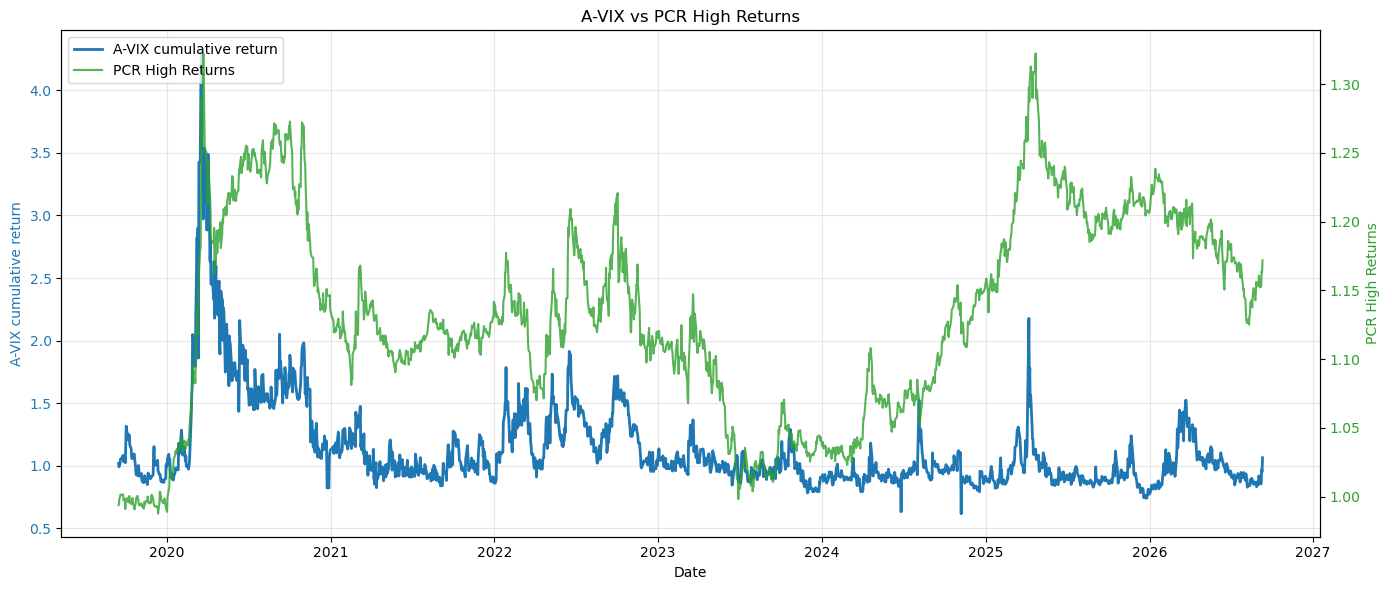


----------------------------------------
	[PCR] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.094479
MAE							: 0.717796
TEV							: 0.004748
Corr						: 0.456357
----------------------------------------


----------------------------------------
	[PCR] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.000598
Volatility	: 0.117040
Gross Returns		: 0.005244
Transaction Cost	: 0.003472
Short borrow Cost	: 0.001160
Turnover (annual)			: 3.472498
Max daily Turnover			: 1.482192
TR (Dhingra)				: 0.542220
Rebalance days (annual)				: 6
Number of trades (annual)			: 32
Average Holdings			: 4
----------------------------------------



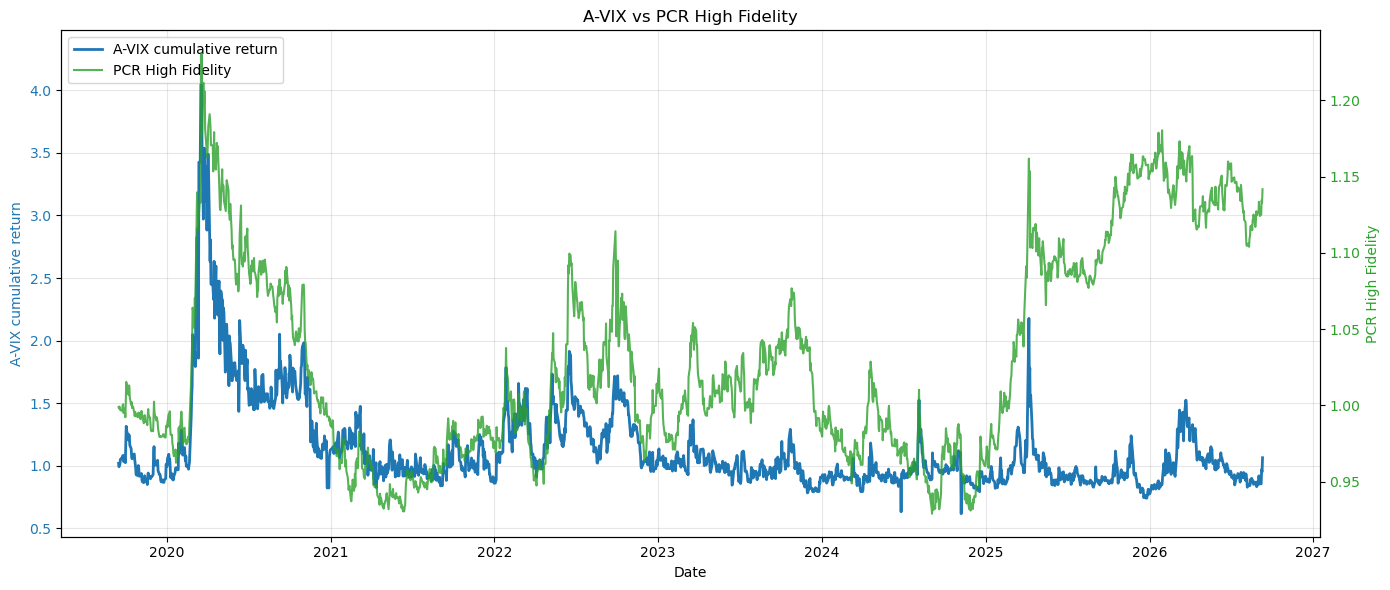

In [7]:
#####################
# PCR - High Returns
#####################
TRN_WINDOW = 190
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16

y_pred_pcr, y_pred_portfolio_pcr_high_returns, reconst_pcr, pcr_components, pcr_coeff, pcr_weights, pcr_qp_weights, pcr_trading, gross_returns_pcr = sliding_walk_forward('PCR',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr)
y_pred_portfolio_pcr_high_returns = pd.Series(y_pred_portfolio_pcr_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pcr = compute_tracking_metrics('[PCR] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_high_returns)
metrics_trading_pcr = compute_trading_metrics('[PCR] High Returns - Trading Metrics',pcr_trading,y_pred_portfolio_pcr_high_returns,gross_returns_pcr,y.iloc[pred_start:pred_end].values)
pcr_objective = compute_objective(y_pred_portfolio_pcr_high_returns,y.iloc[pred_start:pred_end].values)
#print(pcr_objective)

if PLOT_GRAPH ==True:
    focused_plot('PCR High Returns',y_pred_portfolio_pcr_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)


#####################
# PCR - High Fidelity
#####################
TRN_WINDOW = 320
TST_WINDOW = 40
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 8

y_pred_pcr, y_pred_portfolio_pcr_high_fidelity, reconst_pcr, pcr_components, pcr_coeff, pcr_weights, pcr_qp_weights, pcr_trading, gross_returns_pcr = sliding_walk_forward('PCR',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr)
y_pred_portfolio_pcr_high_fidelity = pd.Series(y_pred_portfolio_pcr_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pcr = compute_tracking_metrics('[PCR] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_high_fidelity)
metrics_trading_pcr = compute_trading_metrics('[PCR] High Fidelity - Trading Metrics',pcr_trading,y_pred_portfolio_pcr_high_fidelity,gross_returns_pcr,y.iloc[pred_start:pred_end].values)
pcr_objective = compute_objective(y_pred_portfolio_pcr_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(pcr_objective)

if PLOT_GRAPH ==True:
    focused_plot('PCR High Fidelity',y_pred_portfolio_pcr_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)



#### **3.2 Partial Least Squares (PLS)**
Config parameters obtained by Random Grid Search for the two objective functions


----------------------------------------
	[PLS] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.138917
MAE							: 0.740345
TEV							: 0.005142
Corr						: 0.282972
----------------------------------------


----------------------------------------
	[PLS] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.051667
Volatility	: 0.090035
Gross Returns		: 0.059346
Transaction Cost	: 0.005889
Short borrow Cost	: 0.001387
Turnover (annual)			: 5.888628
Max daily Turnover			: 2.000064
TR (Dhingra)				: 0.696691
Rebalance days (annual)				: 8
Number of trades (annual)			: 41
Average Holdings			: 4
----------------------------------------



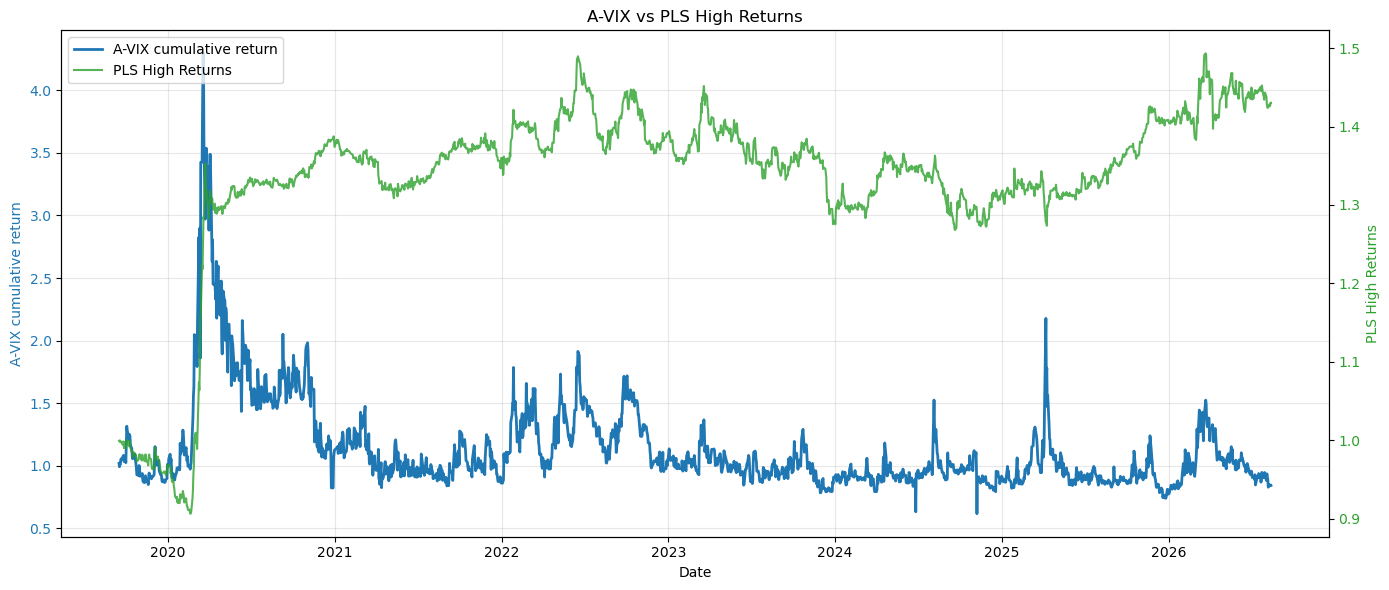


----------------------------------------
	[PLS] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.113336
MAE							: 0.731369
TEV							: 0.004914
Corr						: 0.383601
----------------------------------------


----------------------------------------
	[PLS] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.049782
Volatility	: 0.086264
Gross Returns		: 0.057550
Transaction Cost	: 0.005992
Short borrow Cost	: 0.001383
Turnover (annual)			: 5.991803
Max daily Turnover			: 1.996668
TR (Dhingra)				: 0.470453
Rebalance days (annual)				: 13
Number of trades (annual)			: 56
Average Holdings			: 4
----------------------------------------



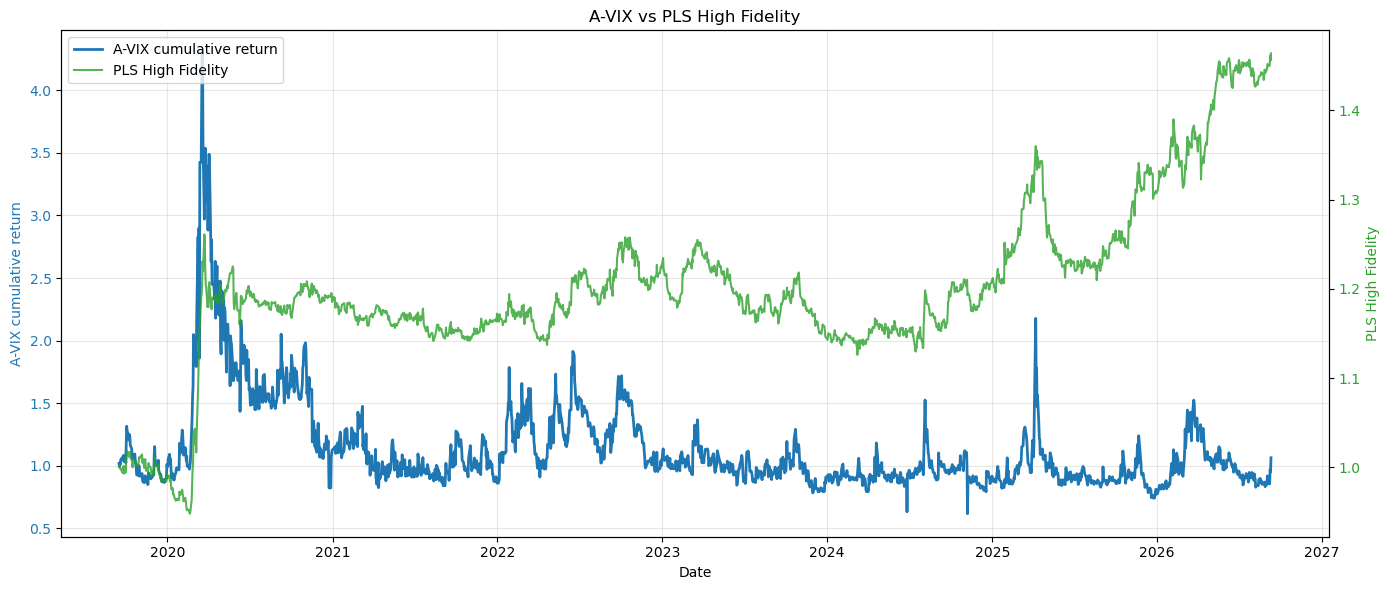

In [8]:
###################
# PLS - High Returns
###################
TRN_WINDOW = 230
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 8

y_pred_pls, y_pred_portfolio_pls_high_returns, reconst_pls, pls_components, pls_coeff, pls_weights, pls_qp_weights, pls_trading,gross_returns_pls = sliding_walk_forward('PLS',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls)
y_pred_portfolio_pls_high_returns = pd.Series(y_pred_portfolio_pls_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pls = compute_tracking_metrics('[PLS] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_high_returns)
metrics_trading_pls = compute_trading_metrics('[PLS] High Returns - Trading Metrics',pls_trading,y_pred_portfolio_pls_high_returns,gross_returns_pls,y.iloc[pred_start:pred_end].values)
pls_objective = compute_objective(y_pred_portfolio_pls_high_returns,y.iloc[pred_start:pred_end].values)
#print(pls_objective)

if PLOT_GRAPH ==True:
    focused_plot('PLS High Returns',y_pred_portfolio_pls_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)



######################
# PLS - High Fidelity
######################
TRN_WINDOW = 300
TST_WINDOW = 20
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 6

y_pred_pls, y_pred_portfolio_pls_high_fidelity, reconst_pls, pls_components, pls_coeff, pls_weights, pls_qp_weights, pls_trading,gross_returns_pls = sliding_walk_forward('PLS',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW,ncomponents=N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls)
y_pred_portfolio_pls_high_fidelity = pd.Series(y_pred_portfolio_pls_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pls = compute_tracking_metrics('[PLS] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_high_fidelity)
metrics_trading_pls = compute_trading_metrics('[PLS] High Fidelity - Trading Metrics',pls_trading,y_pred_portfolio_pls_high_fidelity,gross_returns_pls,y.iloc[pred_start:pred_end].values)
pls_objective = compute_objective(y_pred_portfolio_pls_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(pls_objective)

if PLOT_GRAPH ==True:
    focused_plot('PLS High Fidelity',y_pred_portfolio_pls_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)



#### **3.3 Elastic Net (EN)**
Config parameters obtained by Random Grid Search for the two objective functions


----------------------------------------
	[EN] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.135070
MAE							: 0.738015
TEV							: 0.005107
Corr						: 0.313090
----------------------------------------


----------------------------------------
	[EN] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.044266
Volatility	: 0.094626
Gross Returns		: 0.051564
Transaction Cost	: 0.005437
Short borrow Cost	: 0.001529
Turnover (annual)			: 5.436643
Max daily Turnover			: 1.998250
TR (Dhingra)				: 0.642204
Rebalance days (annual)				: 8
Number of trades (annual)			: 39
Average Holdings			: 4
----------------------------------------



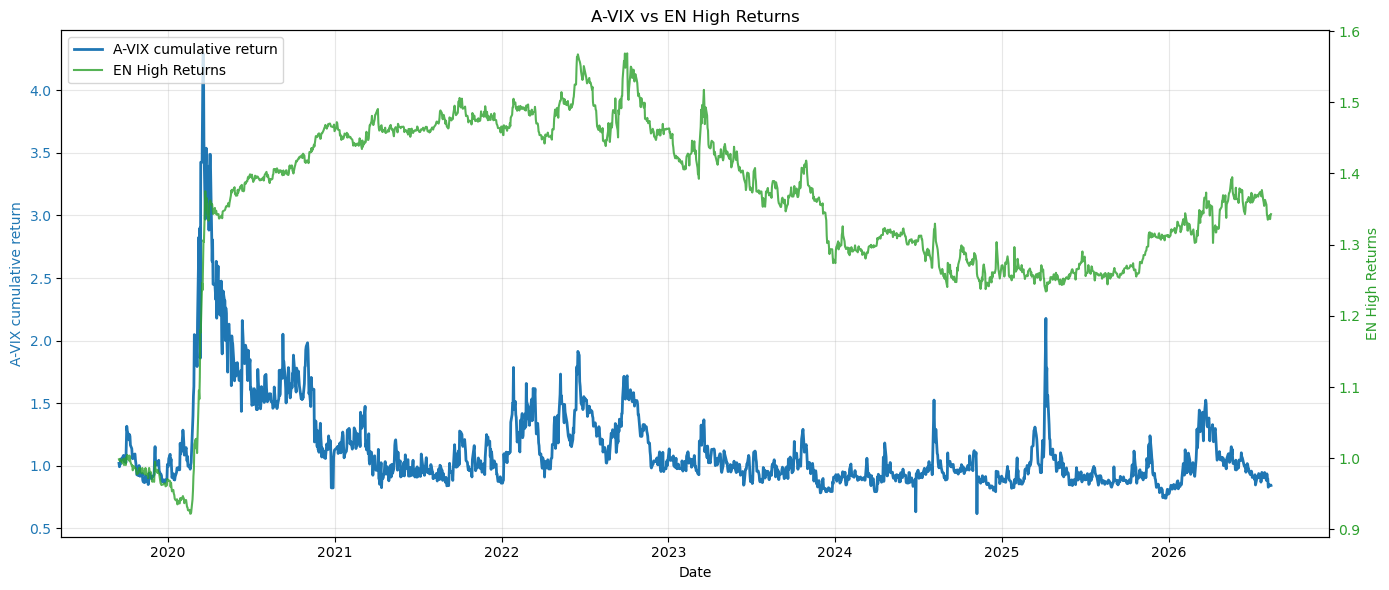


----------------------------------------
	[EN] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.106408
MAE							: 0.726532
TEV							: 0.004853
Corr						: 0.424890
----------------------------------------


----------------------------------------
	[EN] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.021556
Volatility	: 0.095587
Gross Returns		: 0.032368
Transaction Cost	: 0.008827
Short borrow Cost	: 0.001702
Turnover (annual)			: 8.827461
Max daily Turnover			: 2.000141
TR (Dhingra)				: 0.347269
Rebalance days (annual)				: 25
Number of trades (annual)			: 102
Average Holdings			: 4
----------------------------------------



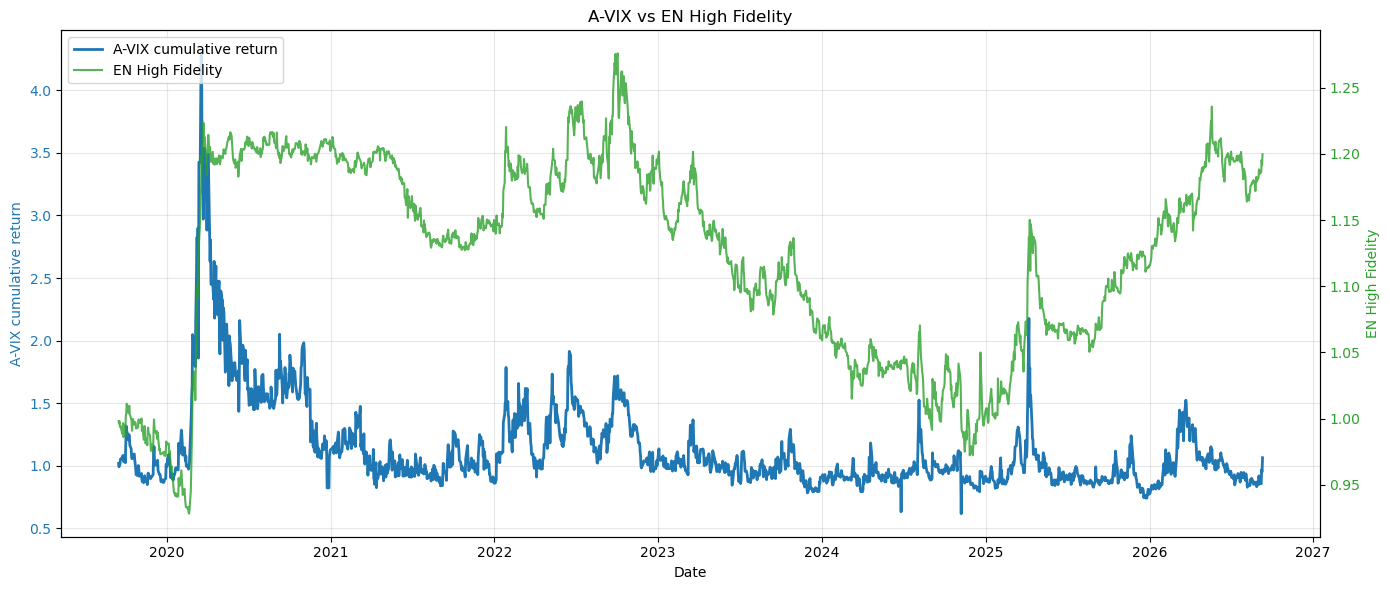

In [9]:
######################################
# Elastic Net (EN) - High Returns
######################################
TRN_WINDOW = 230
TST_WINDOW = 30
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.03 
#N_COMPONENTS = 17

y_pred_en, y_pred_portfolio_en_high_returns, reconst_en, en_components, en_coeff, en_weights, en_qp_weights, en_trading, gross_returns_en = sliding_walk_forward('EN',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en)
y_pred_portfolio_en_high_returns = pd.Series(y_pred_portfolio_en_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_en = compute_tracking_metrics('[EN] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_high_returns)
metrics_trading_en = compute_trading_metrics('[EN] High Returns - Trading Metrics',en_trading,y_pred_portfolio_en_high_returns,gross_returns_en,y.iloc[pred_start:pred_end].values)
en_objective = compute_objective(y_pred_portfolio_en_high_returns,y.iloc[pred_start:pred_end].values)
#print(en_objective)

if PLOT_GRAPH ==True:
    focused_plot('EN High Returns',y_pred_portfolio_en_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)


######################################
# Elastic Net (EN) - High Fidelity
######################################
TRN_WINDOW = 300
TST_WINDOW = 10
#HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
WEIGHT_DEVIATION = 0.04 
#N_COMPONENTS = 17

y_pred_en, y_pred_portfolio_en_high_fidelity, reconst_en, en_components, en_coeff, en_weights, en_qp_weights, en_trading, gross_returns_en = sliding_walk_forward('EN',X,y,screened_prices['^AXVI'],TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en)
y_pred_portfolio_en_high_fidelity = pd.Series(y_pred_portfolio_en_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_en = compute_tracking_metrics('[EN] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_high_fidelity)
metrics_trading_en = compute_trading_metrics('[EN] High Fidelity - Trading Metrics',en_trading,y_pred_portfolio_en_high_fidelity,gross_returns_en,y.iloc[pred_start:pred_end].values)
en_objective = compute_objective(y_pred_portfolio_en_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(en_objective)

if PLOT_GRAPH ==True:
    focused_plot('EN High Fidelity',y_pred_portfolio_en_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)


### **4. Hidden Markov Model**

Model design steps:
1. Feature engineering for HMM
2. Training a Hidden Markov Model (HMM)
3. Predicting hidden states from emissions
4. Estimating state prediction accuracy against hand labelled set.



In [10]:
# Fady: HMM utils
def train_hmm(emissions,n_states = HMM_STATES, covariance_type="diag", n_iter=100, random_state=SEED):

    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    init_params = "stmc"
    means_init = None
    model = hmm.GaussianHMM(
        n_components=n_states,
        covariance_type=covariance_type,
        n_iter=n_iter,
        random_state=random_state,
        init_params=init_params,
    )

    if means_init is not None:
        model.means_ = means_init

    model.fit(X)

    return model

def predict_states(model, emissions):
    X = np.asarray(emissions)

    if X.ndim == 1:
        X = X.reshape(-1, 1)

    states = model.predict(X)

    return states

def reorder_states_by_avix_mean(states,avix_values):
    # Fady: renumber states so state 0 has the lowest A-VIX mean and state HMM_STATES-1 has the highest A-VIX mean.
    states = np.asarray(states)
    avix_values = np.asarray(avix_values)

    state_means = {}

    for state in range(HMM_STATES):
        state_values = avix_values[states == state]

        if len(state_values) > 0:
            state_means[state] = np.mean(state_values)
        else:
            state_means[state] = np.inf

    state_order = sorted(state_means,key=state_means.get)
    state_map = {old_state:new_state for new_state,old_state in enumerate(state_order)}

    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states,state_map

def apply_state_map(states,state_map):
    states = np.asarray(states)
    reordered_states = np.array([state_map[state] for state in states])

    return reordered_states

def evaluate_state_predictions( true_states, predicted_states):
    metrics = {
        "accuracy": accuracy_score(
            true_states,
            predicted_states
        ),
        "precision_macro": precision_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "recall_macro": recall_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "f1_macro": f1_score(
            true_states,
            predicted_states,
            average="macro",
            zero_division=0,
        ),
        "confusion_matrix": confusion_matrix(
            true_states,
            predicted_states,
        ),
        "classification_report": classification_report(
            true_states,
            predicted_states,
            zero_division=0,
        ),
    }

    return metrics

def plot_column_histograms( data, bins=50, figsize=(8, 5)):
    if not isinstance(data, pd.DataFrame):
        data = pd.DataFrame(data)

    for col in data.columns:
        plt.figure(figsize=figsize)
        plt.hist(data[col].dropna(), bins=bins, edgecolor="black")
        plt.title(f"Histogram of {col}")
        plt.xlabel(col)
        plt.ylabel("Frequency")
        plt.grid(True, alpha=0.3)
        plt.show()

def plot_series_and_states(y, states):
    if isinstance(y,pd.Series):
        dates = y.index
    else:
        dates = np.arange(len(y))

    y = np.asarray(y)
    states = np.asarray(states)

    # Fady: count the number of days on which the state differs from the previous day's state
    state_transitions = int(np.sum(states[1:] != states[:-1]))
    print(f"\n\nNumber of state transitions: {state_transitions}")
    print('\n\n')

    colors = {
        0: "tab:blue",
        1: "tab:orange",
        2: "tab:green"
    }
    colors = {state:colors[state] for state in range(HMM_STATES)}

    fig, ax1 = plt.subplots(figsize=(14, 6))

    # Plot continuous line with segment colours determined by state
    if isinstance(dates,pd.DatetimeIndex):
        x_values = mdates.date2num(dates)
        ax1.xaxis_date()
    else:
        x_values = np.asarray(dates,dtype=float)

    segments = np.stack(
        [np.column_stack([x_values[:-1],y[:-1]]),np.column_stack([x_values[1:],y[1:]])],
        axis=1
    )
    segment_colors = [colors.get(state,"black") for state in states[:-1]]

    ax1.add_collection(LineCollection(segments,colors=segment_colors,linewidths=1.5))
    ax1.autoscale_view()

    # Dummy lines for legend
    for state, color in colors.items():
        ax1.plot([], [], color=color, linewidth=2,
                 label=f"Series (State {state})")

    ax1.set_xlabel("Date")
    ax1.set_ylabel("A-VIX")
    ax1.grid(True, alpha=0.3)

    # Secondary axis showing the states
    ax2 = ax1.twinx()

    ax2.step(
        dates,
        states,
        where="post",
        color="grey",
        #color="white",
        linewidth=2,
        alpha=0.8,
        linestyle="dashed",
        label="State Sequence"
    )

    ax2.set_ylabel("State")
    ax2.set_ylim(-0.5, HMM_STATES-0.5)
    ax2.set_yticks(range(HMM_STATES))

    # Combined legend
    h1, l1 = ax1.get_legend_handles_labels()
    h2, l2 = ax2.get_legend_handles_labels()
    ax1.legend(h1 + h2, l1 + l2, loc="upper left")

    plt.title(str(HMM_STATES)+"-state HMM model")
    plt.tight_layout()
    os.makedirs('./figs',exist_ok=True)
    plt.savefig('./figs/'+ str(HMM_STATES)+"-state HMM model" +'.png', format='png',dpi=300, bbox_inches="tight")
    plt.show()


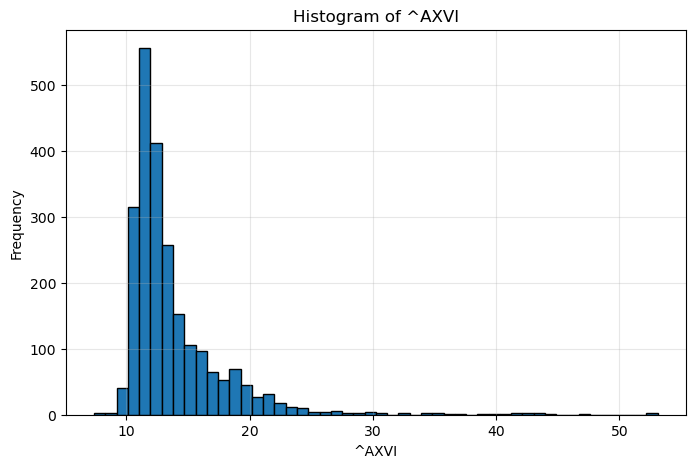

In [11]:
np.random.seed(SEED)

if PLOT_GRAPH ==True:
    plot_column_histograms(screened_prices['^AXVI'])

In [12]:
def hmm_feature_engineering(prices,returns,n_states):
    # Fady: HMM basic feature engineering, use the two main features A-VIX and ASX 200 index
    df_p = prices.copy()
    df_r = returns.copy()

    clms=['^AXVI', 'STW.AX']
    df_p= df_p[clms]
    # Add returns
    df_p['^AXVI_r'] = df_r['^AXVI']
    df_p['STW.AX_r'] = df_r['STW.AX']

    # Fady: simple labeling of the training set
    # state 0 = low A-VIX, state 1 = medium A-VIX, state 2 = high A-VIX
    df_p['state'] =0

    if n_states == 3:
        df_p.loc[df_p['^AXVI']>13, 'state'] = 1
        df_p.loc[df_p['^AXVI']>17, 'state'] = 2

    if n_states == 2:
        df_p.loc[df_p['^AXVI']>16, 'state'] = 1

    # Add EMAs and rolling stats
    clms=['^AXVI', 'STW.AX','^AXVI_r','state']
    for clm in clms:
        #df_p['ema3_'+clm] = df_p[clm].ewm(span=3, adjust=False).mean()
        #df_p['ema3_'+clm].bfill(inplace=True)
        #df_p['ema3_pct_'+clm] = df_p['ema3_'+clm].pct_change()
        #df_p['ema3_pct_'+clm].bfill(inplace=True)

        df_p['ema10_'+clm] = df_p[clm].ewm(span=10, adjust=False).mean()
        df_p['ema10_'+clm] = df_p['ema10_'+clm].bfill()
        df_p['ema10_pct_'+clm] = df_p['ema10_'+clm].pct_change()
        df_p['ema10_pct_'+clm] = df_p['ema10_pct_'+clm].bfill()

        #df_p['std10_'+clm] = df_p[clm].rolling(window=10).std()
        #df_p['std10_'+clm].bfill(inplace=True)
        #df_p['std10_pct_'+clm] = df_p['std10_'+clm].pct_change()
        #df_p['std10_pct_'+clm].bfill(inplace=True)

        #df_p['std20_'+clm] = df_p[clm].rolling(window=20).std()
        #df_p['std20_'+clm].bfill(inplace=True)
        #df_p['std20_pct_'+clm] = df_p['std20_'+clm].pct_change()
        #df_p['std20_pct_'+clm].bfill(inplace=True)

    # handle unexpected values
    for clm in df_p.columns:
        finite_values = df_p.loc[np.isfinite(df_p[clm]),clm]
        df_p[clm] = df_p[clm].replace(np.inf,finite_values.max())
        df_p[clm] = df_p[clm].replace(-np.inf,finite_values.min())

    # Fady: smoothed version using EMA instead of actual value.
    df_p['state2'] =0
    if n_states == 3:
        df_p.loc[df_p['ema10_^AXVI']>13, 'state2'] = 1
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 2
    if n_states == 2:
        df_p.loc[df_p['ema10_^AXVI']>17, 'state2'] = 1

    return df_p

df_p = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)
hmm_features=['state2','ema10_state','^AXVI','ema10_^AXVI']



 HMM accuracy:  0.8621877691645133





{'accuracy': 0.8621877691645133,
 'precision_macro': 0.8448284078351348,
 'recall_macro': 0.8376151670206139,
 'f1_macro': 0.8411060908921616,
 'confusion_matrix': array([[1260,  113,    0],
        [ 120,  448,   37],
        [   0,   50,  294]]),
 'classification_report': '              precision    recall  f1-score   support\n\n           0       0.91      0.92      0.92      1373\n           1       0.73      0.74      0.74       605\n           2       0.89      0.85      0.87       344\n\n    accuracy                           0.86      2322\n   macro avg       0.84      0.84      0.84      2322\nweighted avg       0.86      0.86      0.86      2322\n'}






Number of state transitions: 90





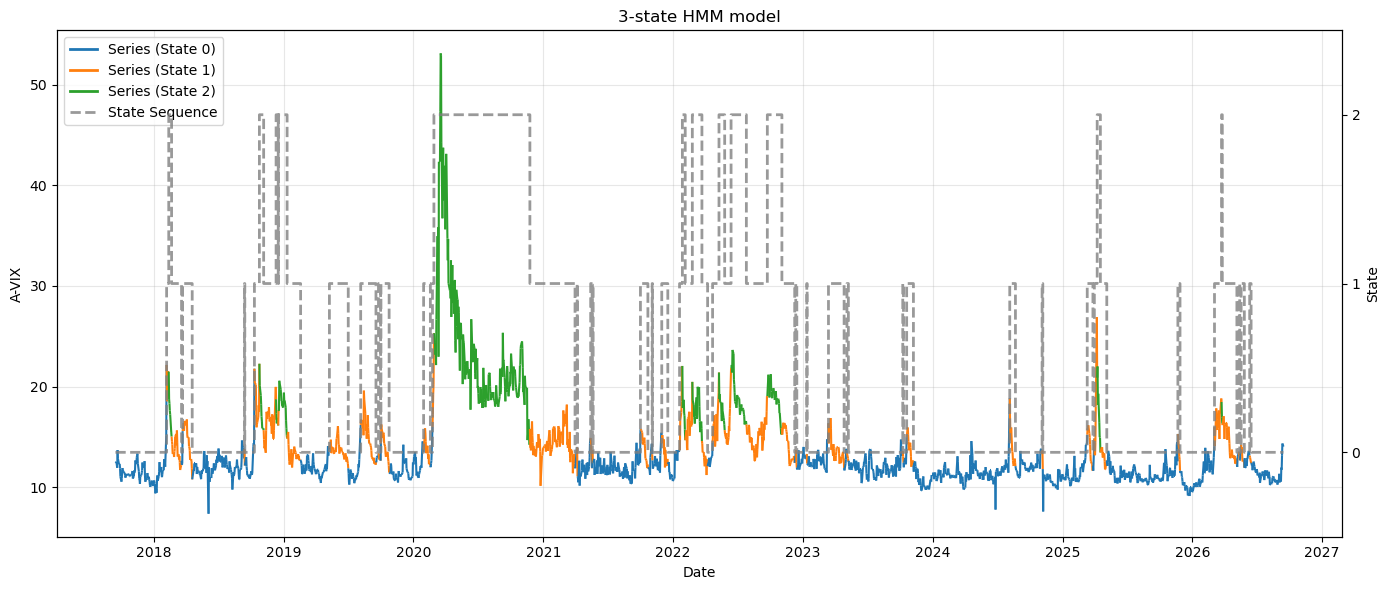

In [13]:
# HMM modeling
hmm_baseline_model = train_hmm( emissions=df_p[hmm_features], n_states=HMM_STATES )
predicted_states = predict_states(  hmm_baseline_model,  df_p[hmm_features] )
predicted_states,state_map = reorder_states_by_avix_mean(predicted_states,df_p['^AXVI'].values)
df_p['pred_state'] = predicted_states


hmm_metrics = evaluate_state_predictions(
    df_p['state'].values,
    df_p['pred_state'].values
)


print('\n HMM accuracy: ', hmm_metrics['accuracy'])
print('\n\n')
display(hmm_metrics)
print('\n\n')

if PLOT_GRAPH ==True:
    plot_series_and_states(df_p['^AXVI'], df_p['pred_state'])


### **5. Expanding window Walk-forward loop for HMM**

1. Generate the train and test pairs for each iteration.
2. Fit the HMM model on the training window data
3. Apply state based PCR, PLS or EN fiting to training window
4. Predict the test window HMM states
5. Calculate the state-based individual securties coeffcients from the factor coefficents.
6. Define state-based portfolio weight constraints guided by the regressions coeffcients after normalisation.
7. Conduct state-based QP weight optimsation to minise tracking error in training window subject to protfolio constraints.
8. Predict portfolio returns over the test window
9. Calculate Tracking and trading metrics at the end of the test window

In [14]:
def expanding_hmm_states(hmm_emissions,initial_train_window_size,test_window_size):
    hmm_states = []
    splits=walk_forward_expanding_window(len(hmm_emissions), initial_train_window_size, test_window_size)
    for split in splits.itertuples():

        hmm_train = hmm_emissions[split.train_start:split.train_end + 1]
        hmm_test  = hmm_emissions[split.test_start:split.test_end + 1]

        hmm_model = train_hmm(hmm_train,n_states=HMM_STATES)
        train_states = predict_states(hmm_model,hmm_train)
        test_states = predict_states(hmm_model,hmm_test)

        # Fady: determine the state order from A-VIX smoother means in the training
        # window only and apply the same state mapping to the test window.
        train_states,state_map = reorder_states_by_avix_mean(
            #train_states,hmm_train['^AXVI'].values
            train_states,hmm_train['ema10_^AXVI'].values
        )
        test_states = apply_state_map(test_states,state_map)
        hmm_states.append((train_states,test_states))

    return hmm_states


# Fady: expanding window loop with HMM state based models
def expanding_walk_forward(title,X_df,y_df,orig_price,hmm_states,initial_train_window_size,test_window_size,ncomponents=None):

    if ncomponents is None:
        ncomponents = N_COMPONENTS

    y_pred = []
    y_pred_portfolio = [] # net portfolio returns (after costs)
    y_pred_portfolio_gross = [] # gross portfolio returns
    pred_states = []
    pcr_ncomponents = []
    trading_records = []
    previous_qp_weights = None
    previous_state = None

    splits=walk_forward_expanding_window(len(X_df), initial_train_window_size, test_window_size)

    if len(hmm_states) != len(splits):
        raise ValueError("hmm_states must contain one entry per expanding-window split.")

    for split,(train_states,test_states) in zip(splits.itertuples(),hmm_states):
        X_train = X_df[split.train_start:split.train_end + 1]
        y_train = y_df[split.train_start:split.train_end + 1]
        X_test  = X_df[split.test_start:split.test_end + 1]

        ypred = np.zeros(len(X_test))
        qp_weights_by_state = {}

        for state in range(HMM_STATES):
            train_mask = train_states == state
            test_mask = test_states == state

            if not np.any(test_mask):
                continue

            X_train_state = X_train.iloc[train_mask]
            y_train_state = y_train.iloc[train_mask]
            X_test_state = X_test.iloc[test_mask]

            # ElasticNetCV needs at least 3 observations for cv=3.
            # Use the expanding training set only if a state is too small.
            if len(X_train_state) < 3:
                X_train_state = X_train
                y_train_state = y_train

            # window_key identifies the state's training and test rows for the fit cache
            window_key = ('expanding',HMM_STATES,split.train_start,split.train_end,split.test_start,split.test_end,state,
                          hash(train_mask.tobytes()),hash(test_mask.tobytes()))

            state_pred,ncomponents_used,coefficients,portfolio_weights,qp_weights = fit_qp_portfolio(
                title,X_train_state,y_train_state,X_test_state,ncomponents,window_key
            )

            if ncomponents_used is not None:
                pcr_ncomponents.append(ncomponents_used)

            qp_weights_by_state[state] = qp_weights.copy()
            ypred[test_mask] = state_pred

        # Fady: newly estimated QP weights for each test day (those of the day's state)
        qp_columns = list(qp_weights.columns)
        daily_qp_weights = np.zeros((len(X_test),len(qp_columns)))

        for state,state_qp_weights in qp_weights_by_state.items():
            daily_qp_weights[test_states == state] = state_qp_weights.iloc[0].values

        # Fady: the portfolio only changes on a regime switch: the state differs from the previous
        # day's state Otherwise the current weights are kept.
        rebalance_opportunities = np.r_[
            previous_qp_weights is None or test_states[0] != previous_state,
            test_states[1:] != test_states[:-1]
        ]

        executed_qp_weights = np.zeros((len(X_test),len(qp_columns)))
        current_weights = None if previous_qp_weights is None else previous_qp_weights.iloc[-1].values

        for day in range(len(X_test)):
            if rebalance_opportunities[day]:
                current_weights = daily_qp_weights[day]
            executed_qp_weights[day] = current_weights

        executed_qp_weights = pd.DataFrame(executed_qp_weights,index=X_test.index,columns=qp_columns)

        trading,ypred_portfolio,ypred_portfolio_gross = trade_portfolio(
            executed_qp_weights,previous_qp_weights,X_test,rebalance_opportunities
        )
        trading_records.append(trading)

        previous_qp_weights = executed_qp_weights.iloc[[-1]].copy()
        previous_state = test_states[-1]

        y_pred.extend(list(ypred))
        y_pred_portfolio.extend(list(ypred_portfolio))
        y_pred_portfolio_gross.extend(list(ypred_portfolio_gross))
        pred_states.extend(list(test_states))

    reconst = walk_forward_reconst(y_pred_portfolio,orig_price,splits)

    trading_records = pd.concat(trading_records)

    return y_pred, y_pred_portfolio, reconst, pcr_ncomponents, pred_states, coefficients, portfolio_weights, qp_weights, trading_records,y_pred_portfolio_gross



#### **5.1 HMM & PCR**
Config parameters obtained by Random Grid Search for the two objective functions

Model is not converging.  Current: 451.39627210435367 is not greater than 451.5371973750163. Delta is -0.14092527066264893
Model is not converging.  Current: 539.982615607555 is not greater than 540.1617480671929. Delta is -0.1791324596379127



----------------------------------------
	[PCR_HMM] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.108323
MAE							: 0.724820
TEV							: 0.004871
Corr						: 0.348616
----------------------------------------


----------------------------------------
	[PCR_HMM] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.047024
Volatility	: 0.112331
Gross Returns		: 0.064637
Transaction Cost	: 0.015608
Short borrow Cost	: 0.001078
Turnover (annual)			: 15.607681
Max daily Turnover			: 2.000316
TR (Dhingra)				: 1.776247
Rebalance days (annual)				: 9
Number of trades (annual)			: 81
Average Holdings			: 5
----------------------------------------



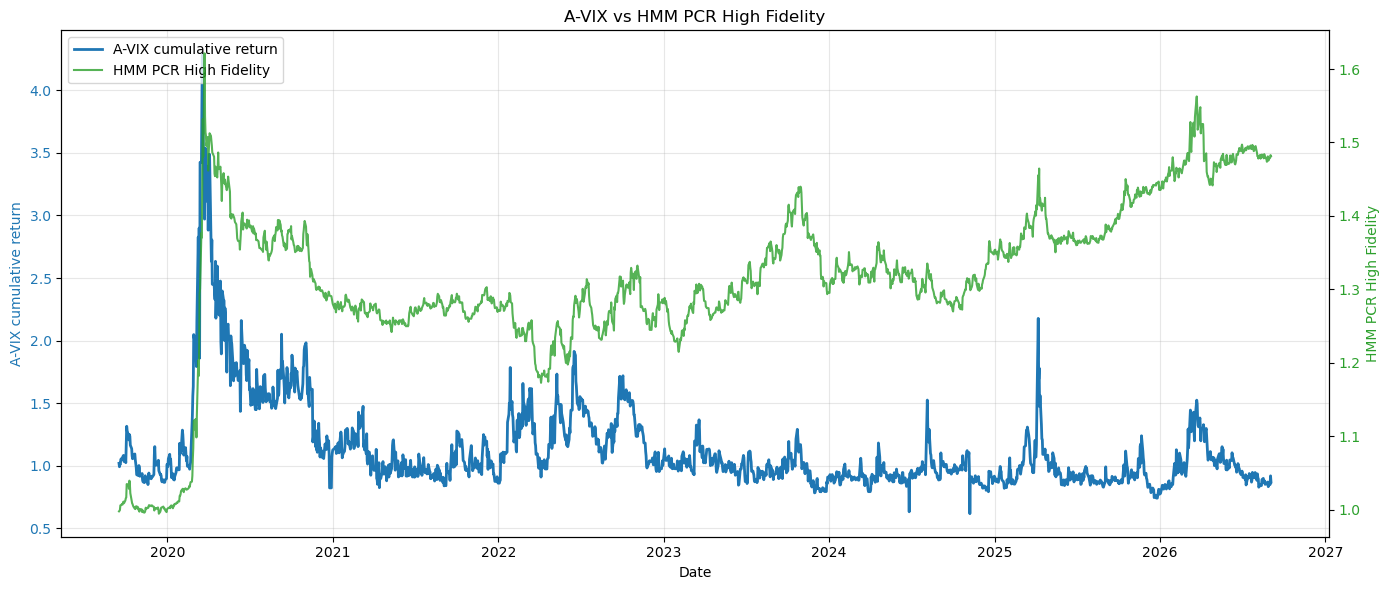

Model is not converging.  Current: 566.5025344922343 is not greater than 566.5133182743143. Delta is -0.010783782080011406



----------------------------------------
	[PCR_HMM] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.109843
MAE							: 0.725841
TEV							: 0.004884
Corr						: 0.299563
----------------------------------------


----------------------------------------
	[PCR_HMM] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.051479
Volatility	: 0.135890
Gross Returns		: 0.061793
Transaction Cost	: 0.008892
Short borrow Cost	: 0.000871
Turnover (annual)			: 8.892128
Max daily Turnover			: 2.000299
TR (Dhingra)				: 1.895595
Rebalance days (annual)				: 5
Number of trades (annual)			: 31
Average Holdings			: 3
----------------------------------------



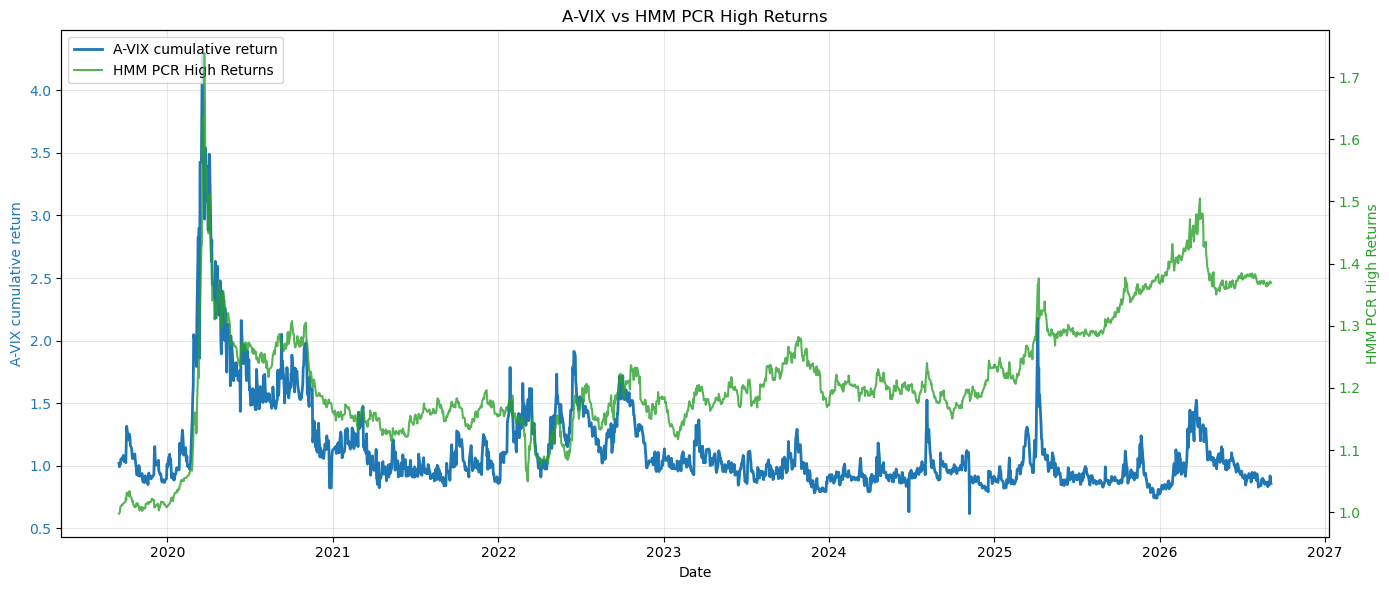

In [15]:
###################################
# Expanding HMM & PCR  - High Fidelity
##################################

TRN_WINDOW = 320
TST_WINDOW = 15 
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.06 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_pcr_exp, y_pred_portfolio_pcr_exp_high_returns, reconst_pcr_exp, pcr_components_exp, pred_states_pcr_exp, hmm_pcr_coeff, hmm_pcr_weights, hmm_pcr_qp_weights, hmm_pcr_trading, gross_returns_pcr_exp = expanding_walk_forward(
    'PCR',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr_exp)
y_pred_portfolio_pcr_exp_high_returns = pd.Series(y_pred_portfolio_pcr_exp_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pcr_exp = compute_tracking_metrics('[PCR_HMM] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_exp_high_returns)
metrics_trading_pcr_exp = compute_trading_metrics('[PCR_HMM] High Fidelity - Trading Metrics',hmm_pcr_trading,y_pred_portfolio_pcr_exp_high_returns,gross_returns_pcr_exp,y.iloc[pred_start:pred_end].values)
pcr_exp_objective = compute_objective(y_pred_portfolio_pcr_exp_high_returns,y.iloc[pred_start:pred_end].values)
#print(pcr_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM PCR High Fidelity',y_pred_portfolio_pcr_exp_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)


###################################
# Expanding HMM & PCR  - High Return
##################################

TRN_WINDOW = 300
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.07 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.03 
N_COMPONENTS = 16

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_pcr_exp, y_pred_portfolio_pcr_exp_high_fidelity, reconst_pcr_exp, pcr_components_exp, pred_states_pcr_exp, hmm_pcr_coeff, hmm_pcr_weights, hmm_pcr_qp_weights, hmm_pcr_trading, gross_returns_pcr_exp = expanding_walk_forward(
    'PCR',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,N_COMPONENTS)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pcr_exp)
y_pred_portfolio_pcr_exp_high_fidelity = pd.Series(y_pred_portfolio_pcr_exp_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pcr_exp = compute_tracking_metrics('[PCR_HMM] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pcr_exp_high_fidelity)
metrics_trading_pcr_exp = compute_trading_metrics('[PCR_HMM] High Returns - Trading Metrics',hmm_pcr_trading,y_pred_portfolio_pcr_exp_high_fidelity,gross_returns_pcr_exp,y.iloc[pred_start:pred_end].values)
pcr_exp_objective = compute_objective(y_pred_portfolio_pcr_exp_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(pcr_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM PCR High Returns',y_pred_portfolio_pcr_exp_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)


#### **5.2 HMM & PLS**
Config parameters obtained by Random Grid Search for the two objective functions

Model is not converging.  Current: 504.84798722783944 is not greater than 504.88561374952377. Delta is -0.03762652168433078
Model is not converging.  Current: 559.1948695775764 is not greater than 559.2026305069969. Delta is -0.00776092942055584



----------------------------------------
	[PLS_HMM] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.128870
MAE							: 0.734810
TEV							: 0.005051
Corr						: 0.297773
----------------------------------------


----------------------------------------
	[PLS_HMM] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.032657
Volatility	: 0.087707
Gross Returns		: 0.047585
Transaction Cost	: 0.013120
Short borrow Cost	: 0.001235
Turnover (annual)			: 13.119739
Max daily Turnover			: 1.999951
TR (Dhingra)				: 1.665092
Rebalance days (annual)				: 8
Number of trades (annual)			: 68
Average Holdings			: 4
----------------------------------------



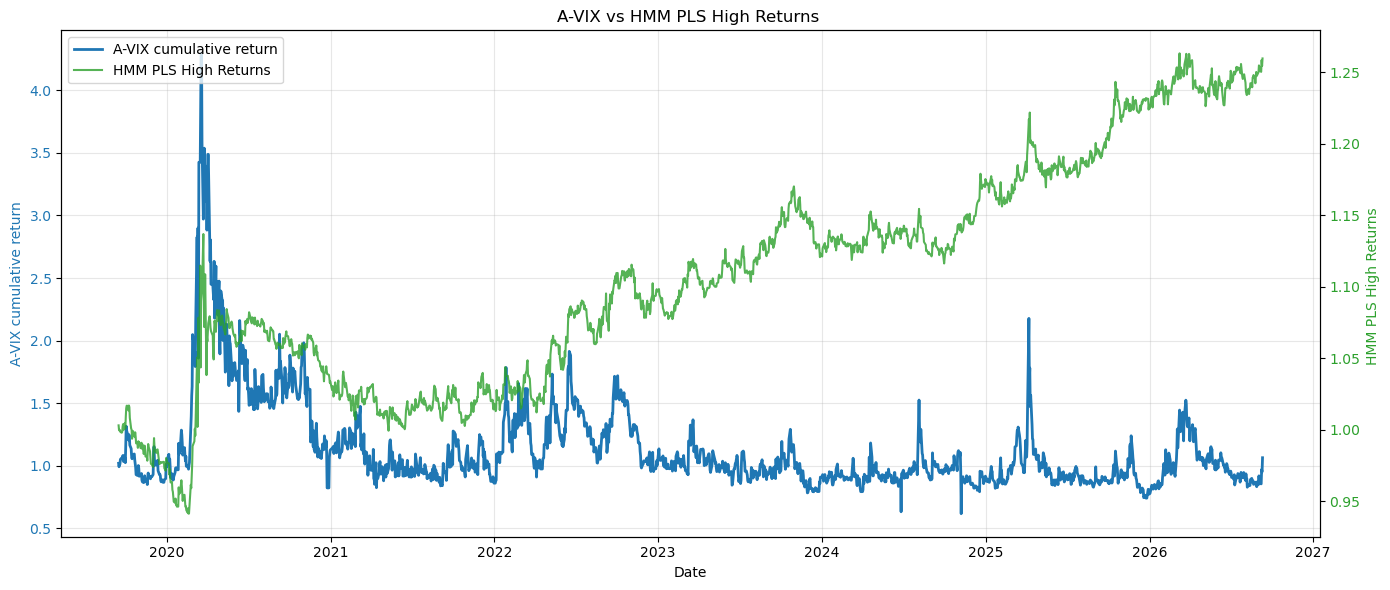

Model is not converging.  Current: 566.5025344922208 is not greater than 566.5133182742973. Delta is -0.010783782076487114



----------------------------------------
	[PLS_HMM] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.117681
MAE							: 0.730810
TEV							: 0.004952
Corr						: 0.327293
----------------------------------------


----------------------------------------
	[PLS_HMM] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.012126
Volatility	: 0.086576
Gross Returns		: 0.021452
Transaction Cost	: 0.007789
Short borrow Cost	: 0.001383
Turnover (annual)			: 7.788750
Max daily Turnover			: 1.859914
TR (Dhingra)				: 1.657033
Rebalance days (annual)				: 5
Number of trades (annual)			: 73
Average Holdings			: 9
----------------------------------------



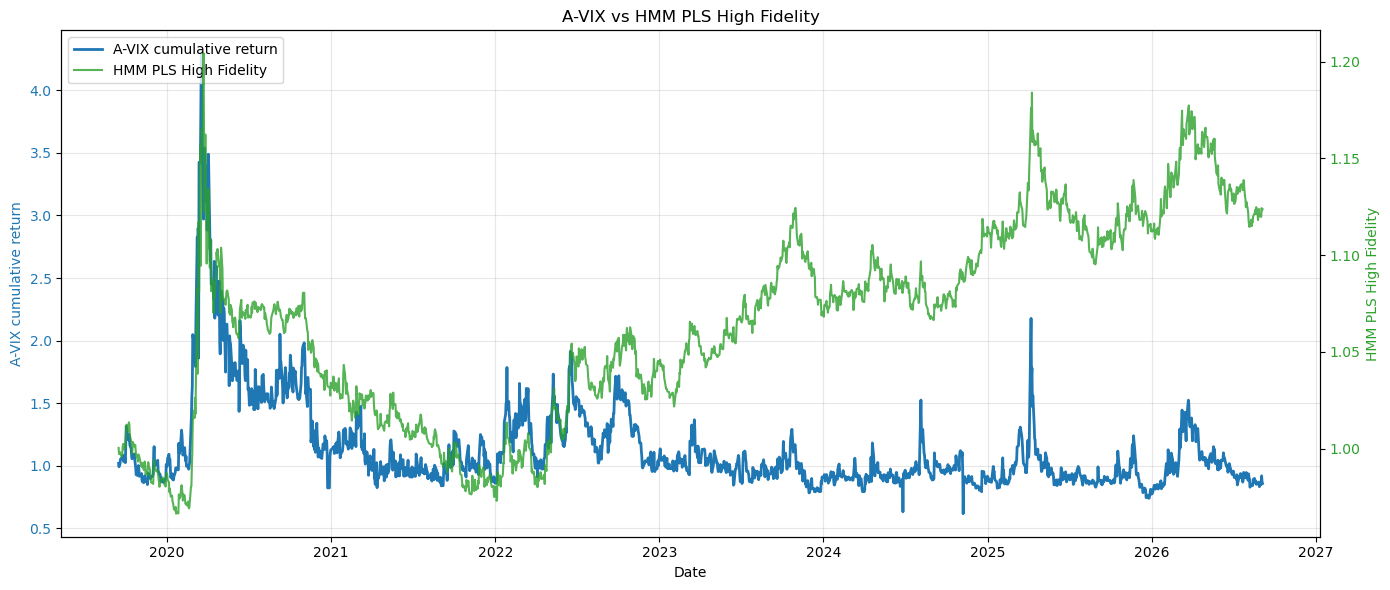

In [16]:
##################################
# Expanding HMM & PLS  - High Returns
##################################
TRN_WINDOW = 190
TST_WINDOW = 15
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.06 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.04 
N_COMPONENTS = 6

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

pls_ncomponents_exp = N_COMPONENTS
y_pred_pls_exp, y_pred_portfolio_pls_exp_high_returns, reconst_pls_exp, pls_components_exp, pred_states_pls_exp, hmm_pls_coeff, hmm_pls_weights, hmm_pls_qp_weights, hmm_pls_trading, gross_returns_pls_exp = expanding_walk_forward(
    'PLS',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,pls_ncomponents_exp)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls_exp)
y_pred_portfolio_pls_exp_high_returns = pd.Series(y_pred_portfolio_pls_exp_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pls_exp = compute_tracking_metrics('[PLS_HMM] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_exp_high_returns)
metrics_trading_pls_exp = compute_trading_metrics('[PLS_HMM] High Returns - Trading Metrics',hmm_pls_trading,y_pred_portfolio_pls_exp_high_returns,gross_returns_pls_exp,y.iloc[pred_start:pred_end].values)
pls_exp_objective = compute_objective(y_pred_portfolio_pls_exp_high_returns,y.iloc[pred_start:pred_end].values)
#print(pls_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM PLS High Returns ',y_pred_portfolio_pls_exp_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)

##################################
# Expanding HMM & PLS  - High Fidelity
##################################
TRN_WINDOW = 300
TST_WINDOW = 63
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.04 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.045 
N_COMPONENTS = 5

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

pls_ncomponents_exp = N_COMPONENTS
y_pred_pls_exp, y_pred_portfolio_pls_exp_high_fidelity, reconst_pls_exp, pls_components_exp, pred_states_pls_exp, hmm_pls_coeff, hmm_pls_weights, hmm_pls_qp_weights, hmm_pls_trading, gross_returns_pls_exp = expanding_walk_forward(
    'PLS',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW,pls_ncomponents_exp)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_pls_exp)
y_pred_portfolio_pls_exp_high_fidelity = pd.Series(y_pred_portfolio_pls_exp_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_pls_exp = compute_tracking_metrics('[PLS_HMM] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_pls_exp_high_fidelity)
metrics_trading_pls_exp = compute_trading_metrics('[PLS_HMM] High Fidelity - Trading Metrics',hmm_pls_trading,y_pred_portfolio_pls_exp_high_fidelity,gross_returns_pls_exp,y.iloc[pred_start:pred_end].values)
pls_exp_objective = compute_objective(y_pred_portfolio_pls_exp_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(pls_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM PLS High Fidelity',y_pred_portfolio_pls_exp_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)





#### **5.3 HMM & EN**
Config parameters obtained by Random Grid Search for the two objective functions


----------------------------------------
	[EN_HMM] High Returns - Tracking Metrics
----------------------------------------
RMSE						: 1.132659
MAE							: 0.740320
TEV							: 0.005085
Corr						: 0.367375
----------------------------------------


----------------------------------------
	[EN_HMM] High Returns - Trading Metrics
----------------------------------------
Net Returns		: 0.026407
Volatility	: 0.086866
Gross Returns		: 0.045096
Transaction Cost	: 0.016555
Short borrow Cost	: 0.001492
Turnover (annual)			: 16.555318
Max daily Turnover			: 2.000033
TR (Dhingra)				: 1.310347
Rebalance days (annual)				: 13
Number of trades (annual)			: 73
Average Holdings			: 3
----------------------------------------



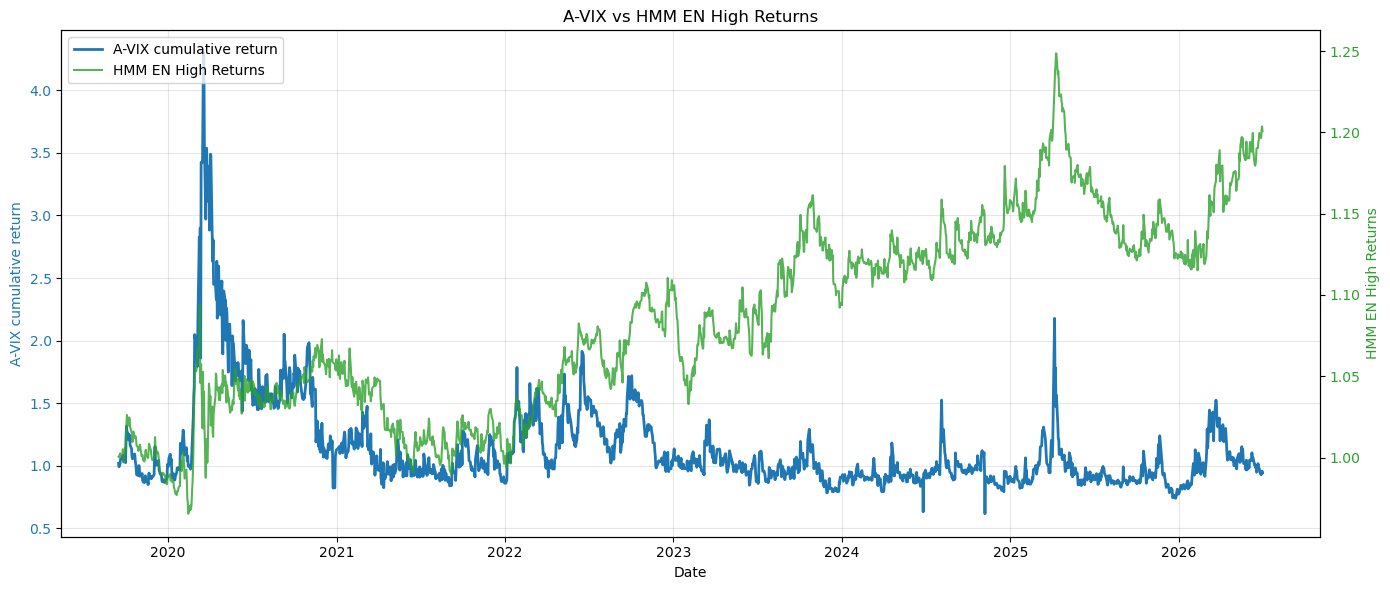


----------------------------------------
	[EN_HMM] High Fidelity - Tracking Metrics
----------------------------------------
RMSE						: 1.123578
MAE							: 0.733107
TEV							: 0.005004
Corr						: 0.307767
----------------------------------------


----------------------------------------
	[EN_HMM] High Fidelity - Trading Metrics
----------------------------------------
Net Returns		: 0.004826
Volatility	: 0.102728
Gross Returns		: 0.014138
Transaction Cost	: 0.007707
Short borrow Cost	: 0.001518
Turnover (annual)			: 7.707131
Max daily Turnover			: 2.000064
TR (Dhingra)				: 1.701608
Rebalance days (annual)				: 5
Number of trades (annual)			: 38
Average Holdings			: 4
----------------------------------------



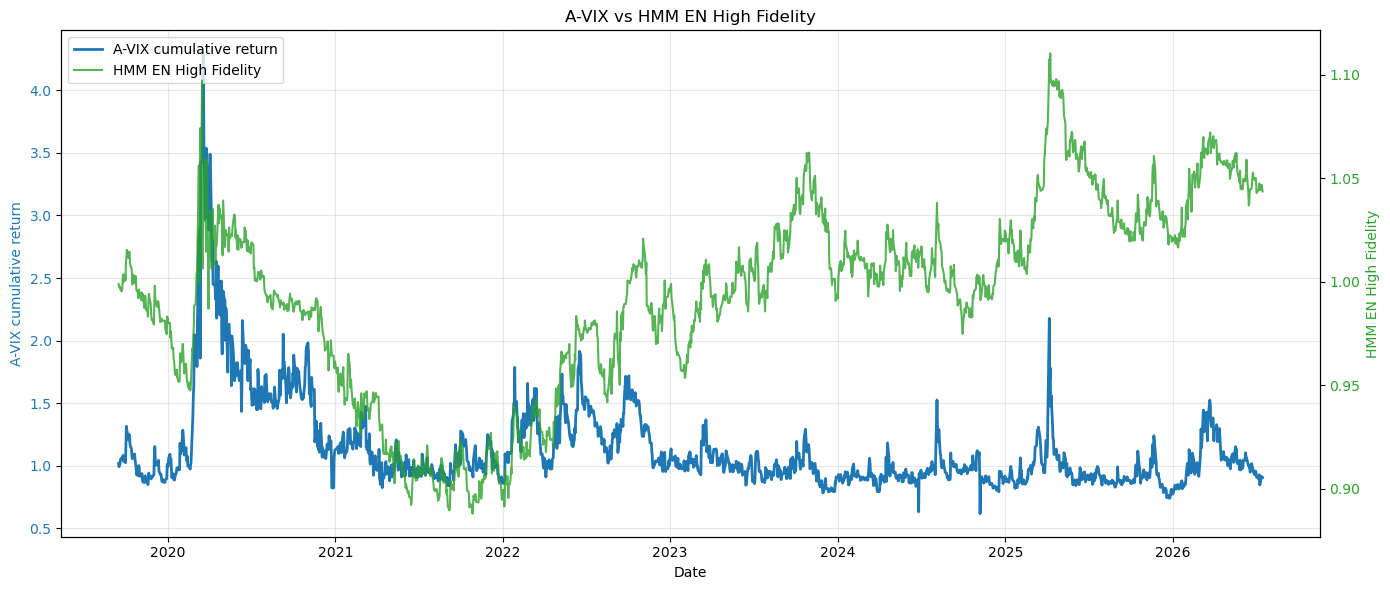

In [17]:
###########################################
# Expanding HMM + Elastic Net  - High Returns
###########################################
TRN_WINDOW = 380 
TST_WINDOW = 63
HMM_STATES = 3
MIN_ABS_WEIGHT = 0.07 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.04 
#N_COMPONENTS = 17

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_en_exp, y_pred_portfolio_en_exp_high_returns, reconst_en_exp, en_components_exp, pred_states_en_exp, hmm_en_coeff, hmm_en_weights, hmm_en_qp_weights, hmm_en_trading, gross_returns_en_exp = expanding_walk_forward(
    'EN',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en_exp)
y_pred_portfolio_en_exp_high_returns = pd.Series(y_pred_portfolio_en_exp_high_returns,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_en_exp = compute_tracking_metrics('[EN_HMM] High Returns - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_exp_high_returns)
metrics_trading_en_exp = compute_trading_metrics('[EN_HMM] High Returns - Trading Metrics',hmm_en_trading,y_pred_portfolio_en_exp_high_returns,gross_returns_en_exp,y.iloc[pred_start:pred_end].values)
en_exp_objective = compute_objective(y_pred_portfolio_en_exp_high_returns,y.iloc[pred_start:pred_end].values)
#print(en_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM EN High Returns',y_pred_portfolio_en_exp_high_returns,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)

###########################################
# Expanding HMM + Elastic Net  - High Fidelity
###########################################
TRN_WINDOW = 300 
TST_WINDOW = 55
HMM_STATES = 2
MIN_ABS_WEIGHT = 0.06 
MIN_REL_WEIGHT_CHANGE = 0.01
WEIGHT_DEVIATION = 0.04 
#N_COMPONENTS = 17

hmm_emissions = hmm_feature_engineering(screened_prices,screened_returns,HMM_STATES)[hmm_features].copy()
hmm_states = expanding_hmm_states(hmm_emissions,TRN_WINDOW,TST_WINDOW)

y_pred_en_exp, y_pred_portfolio_en_exp_high_fidelity, reconst_en_exp, en_components_exp, pred_states_en_exp, hmm_en_coeff, hmm_en_weights, hmm_en_qp_weights, hmm_en_trading, gross_returns_en_exp = expanding_walk_forward(
    'EN',X,y,screened_prices['^AXVI'],hmm_states,TRN_WINDOW,TST_WINDOW)

pred_start = TRN_WINDOW
pred_end = pred_start + len(y_pred_en_exp)
y_pred_portfolio_en_exp_high_fidelity = pd.Series(y_pred_portfolio_en_exp_high_fidelity,index=y.index[pred_start:pred_end])  # net returns with their test dates

metrics_portfolio_en_exp = compute_tracking_metrics('[EN_HMM] High Fidelity - Tracking Metrics',y.iloc[pred_start:pred_end].values,y_pred_portfolio_en_exp_high_fidelity)
metrics_trading_en_exp = compute_trading_metrics('[EN_HMM] High Fidelity - Trading Metrics',hmm_en_trading,y_pred_portfolio_en_exp_high_fidelity,gross_returns_en_exp,y.iloc[pred_start:pred_end].values)
en_exp_objective = compute_objective(y_pred_portfolio_en_exp_high_fidelity,y.iloc[pred_start:pred_end].values)
#print(en_exp_objective)

if PLOT_GRAPH ==True:
    focused_plot('HMM EN High Fidelity',y_pred_portfolio_en_exp_high_fidelity,y.iloc[pred_start:pred_end],PLT_STRT_DATE,PLT_END_DATE)



### **6. Visualisation**
Portfolio cumulative net returns against the A-VIX:
1. The two scenarios of each algorithm
2. The six algorithms of each scenario.

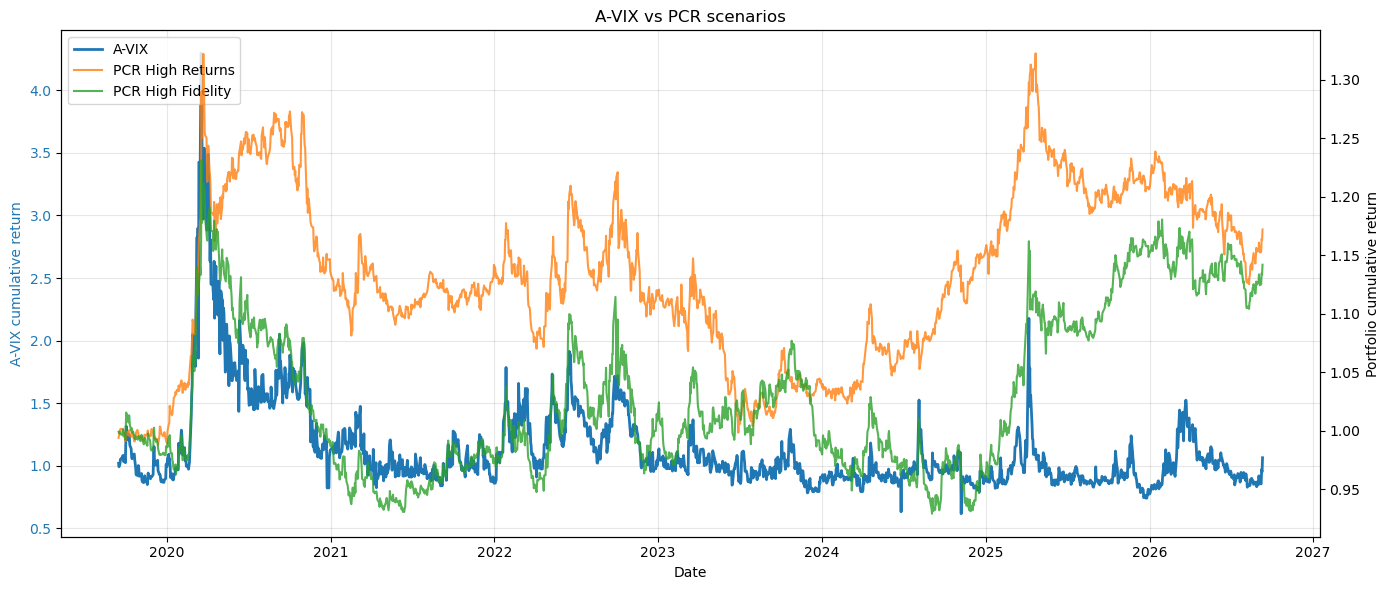

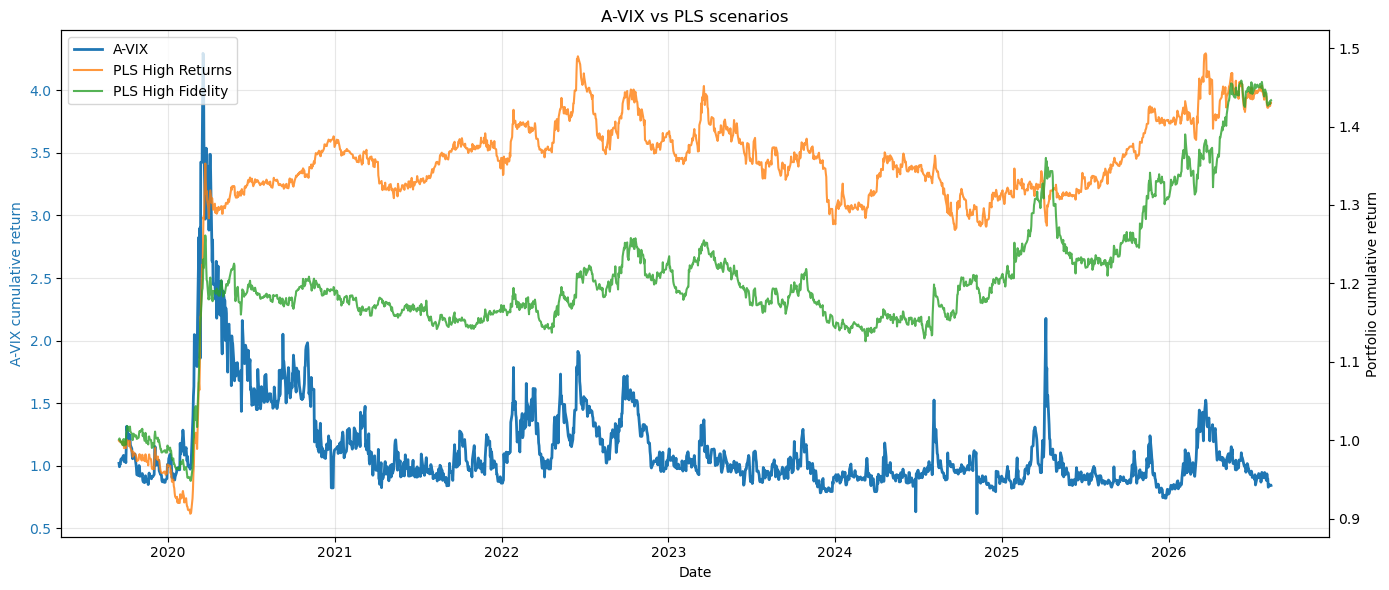

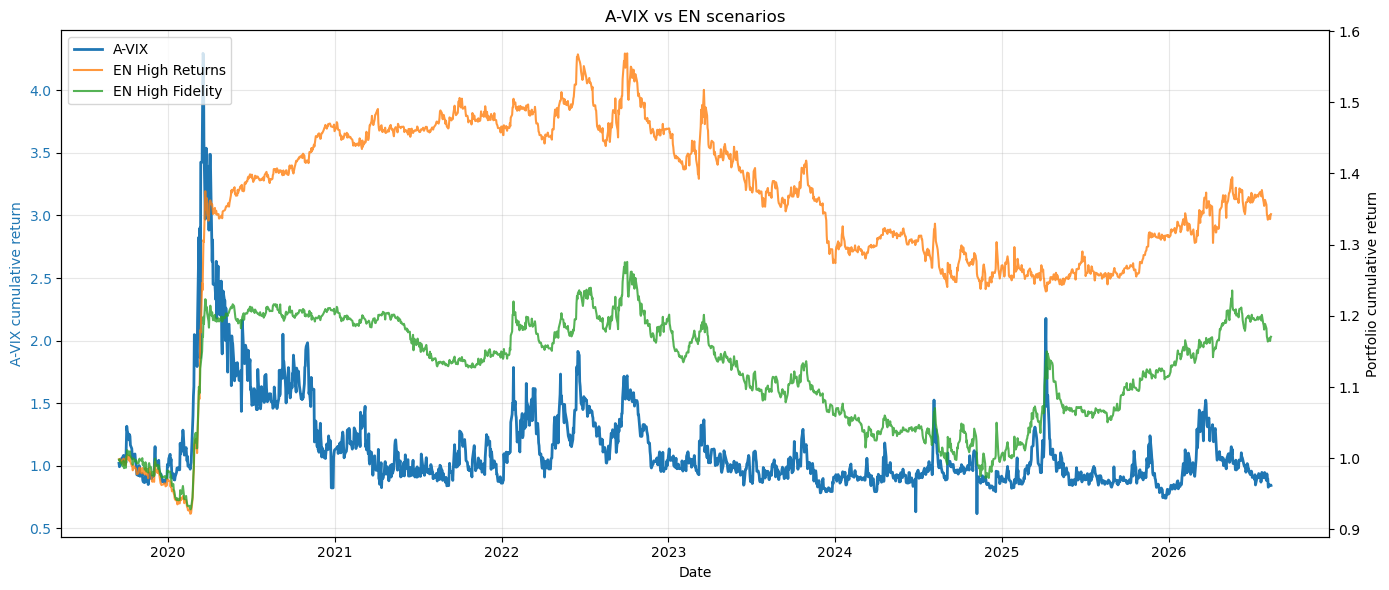

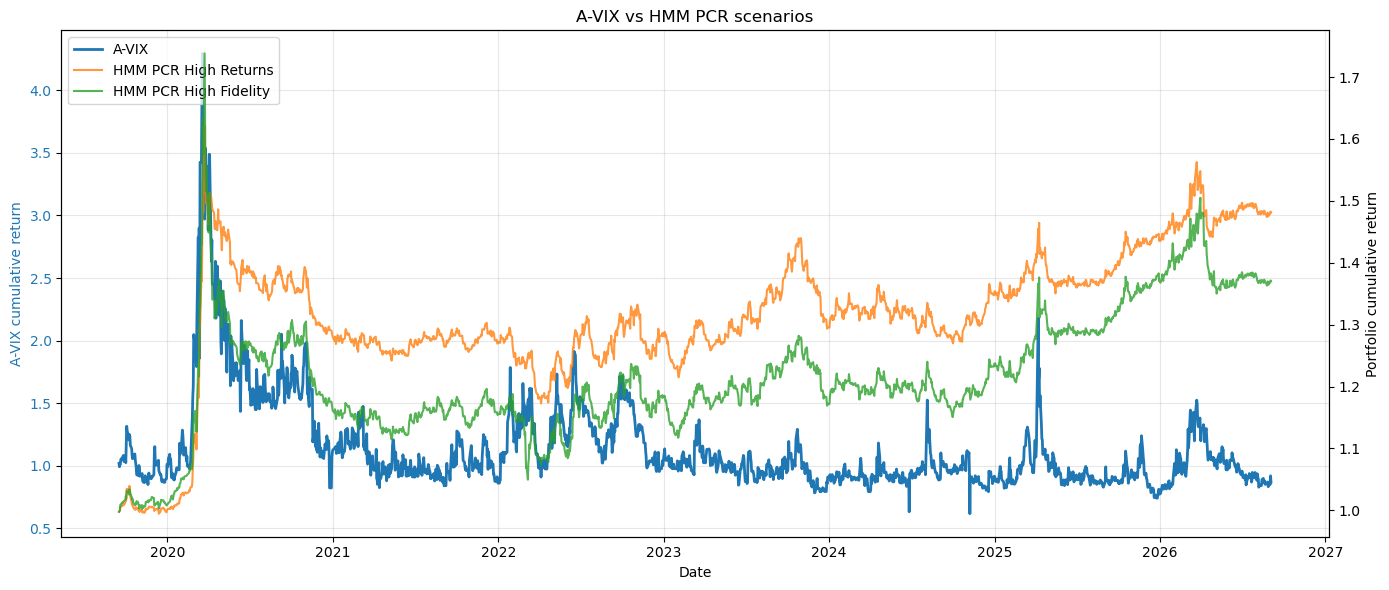

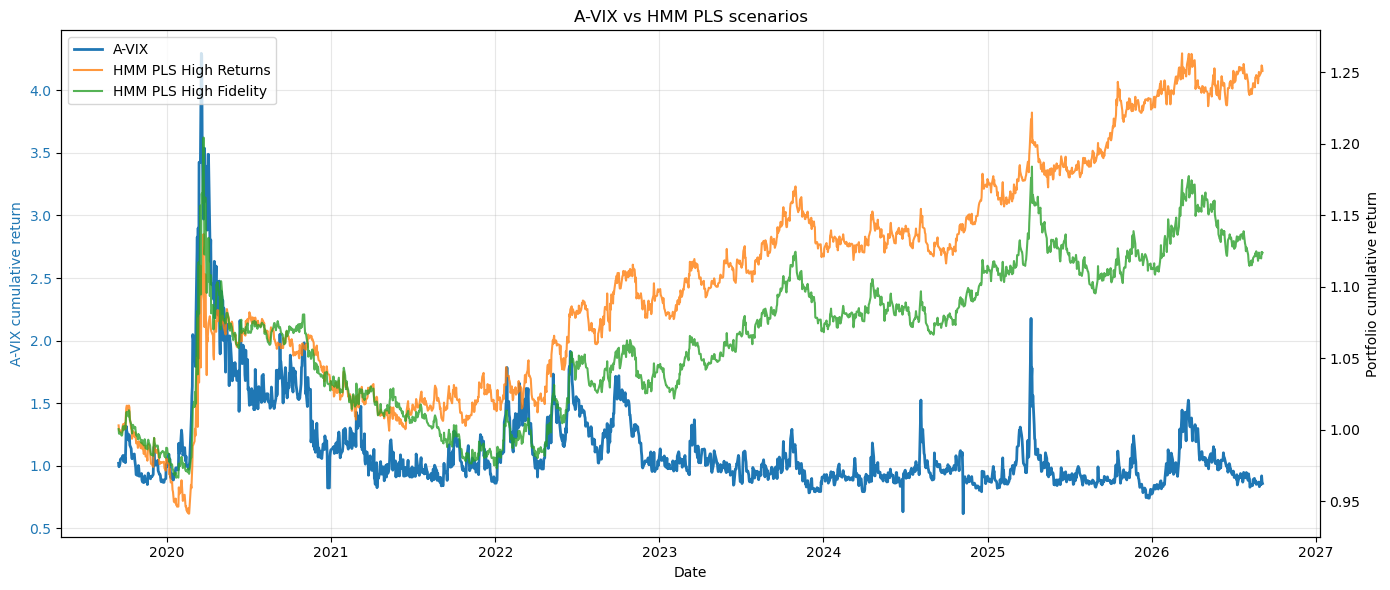

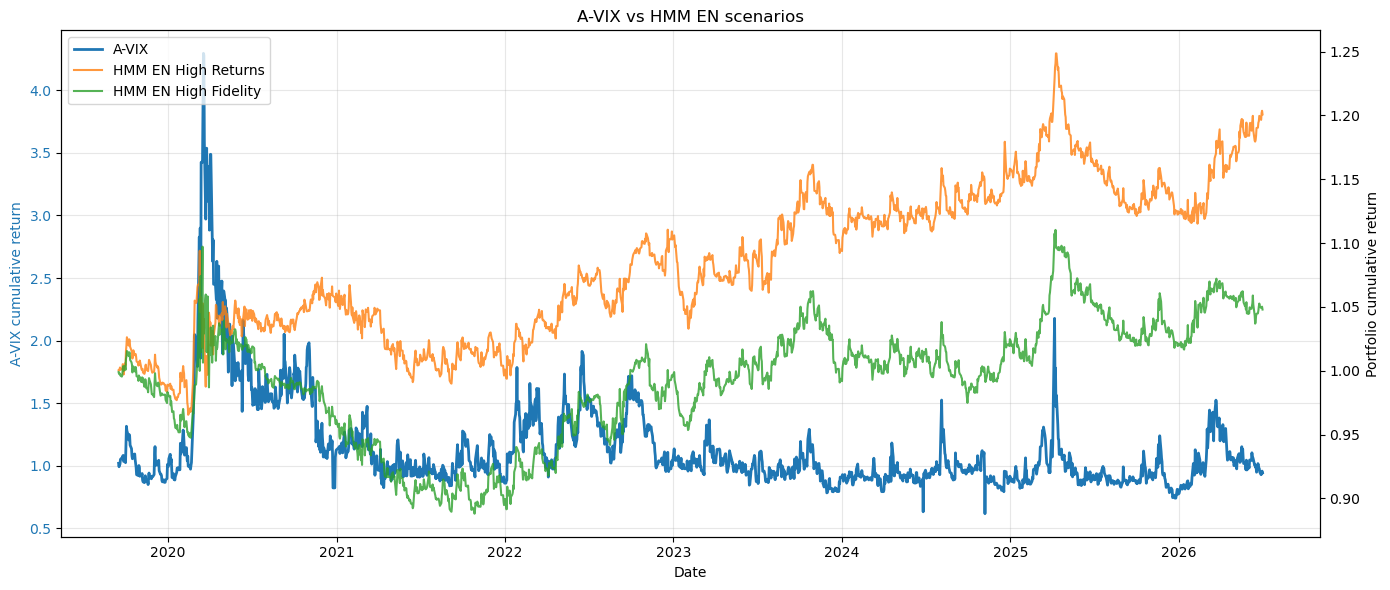

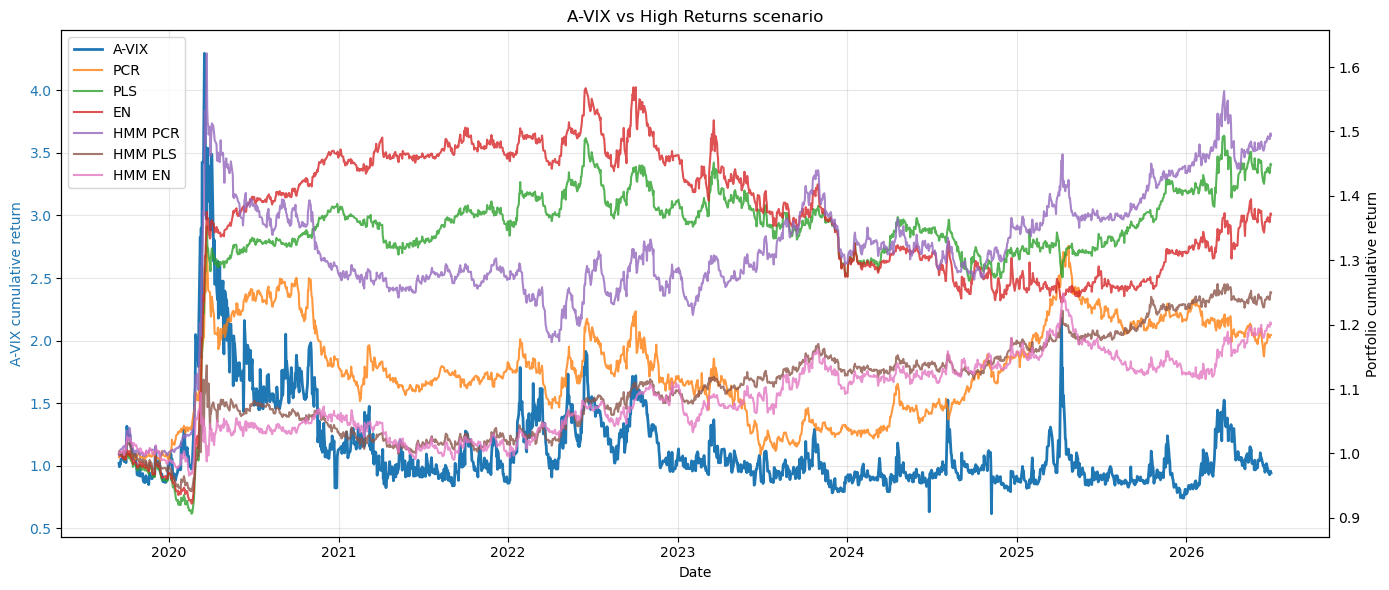

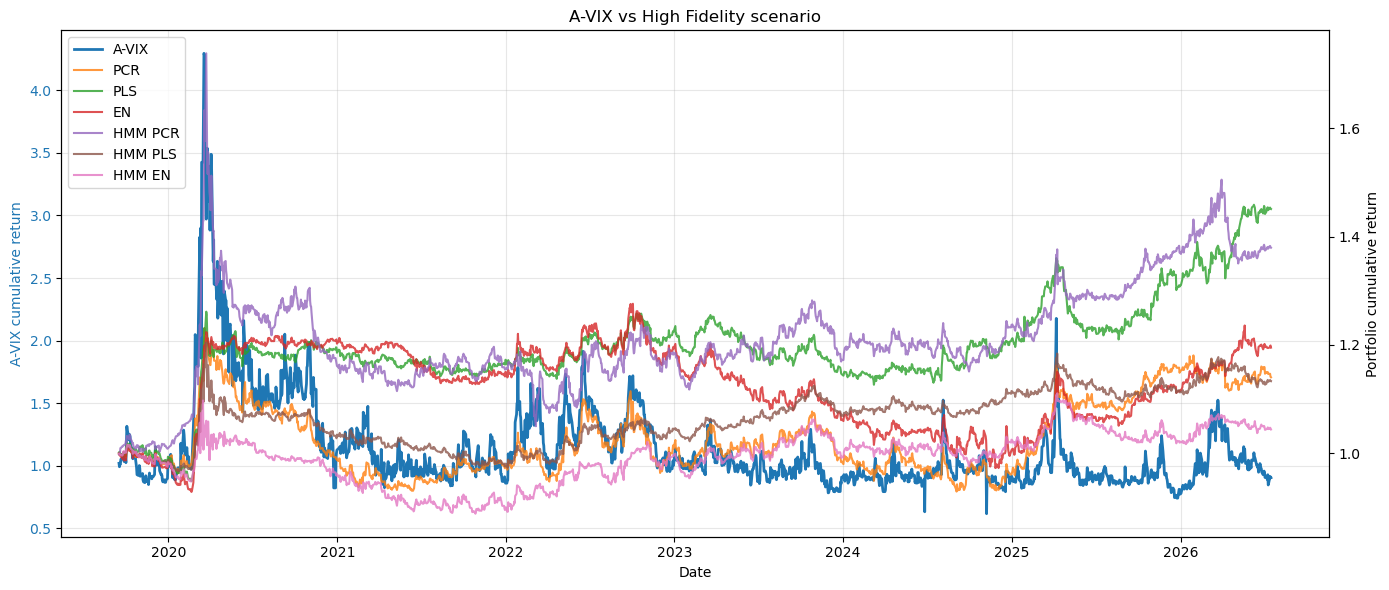

In [18]:
if PLOT_GRAPH ==True:

    # (a) scenarios of each algorithm
    focused_plot_multiple('PCR scenarios',[
        (y_pred_portfolio_pcr_high_returns,'PCR High Returns'),
        (y_pred_portfolio_pcr_high_fidelity,'PCR High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('PLS scenarios',[
        (y_pred_portfolio_pls_high_returns,'PLS High Returns'),
        (y_pred_portfolio_pls_high_fidelity,'PLS High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('EN scenarios',[
        (y_pred_portfolio_en_high_returns,'EN High Returns'),
        (y_pred_portfolio_en_high_fidelity,'EN High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('HMM PCR scenarios',[
        (y_pred_portfolio_pcr_exp_high_returns,'HMM PCR High Returns'),
        (y_pred_portfolio_pcr_exp_high_fidelity,'HMM PCR High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('HMM PLS scenarios',[
        (y_pred_portfolio_pls_exp_high_returns,'HMM PLS High Returns'),
        (y_pred_portfolio_pls_exp_high_fidelity,'HMM PLS High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('HMM EN scenarios',[
        (y_pred_portfolio_en_exp_high_returns,'HMM EN High Returns'),
        (y_pred_portfolio_en_exp_high_fidelity,'HMM EN High Fidelity'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    # (b) algorithms of each scenario
    focused_plot_multiple('High Returns scenario',[
        (y_pred_portfolio_pcr_high_returns,'PCR'),
        (y_pred_portfolio_pls_high_returns,'PLS'),
        (y_pred_portfolio_en_high_returns,'EN'),
        (y_pred_portfolio_pcr_exp_high_returns,'HMM PCR'),
        (y_pred_portfolio_pls_exp_high_returns,'HMM PLS'),
        (y_pred_portfolio_en_exp_high_returns,'HMM EN'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

    focused_plot_multiple('High Fidelity scenario',[
        (y_pred_portfolio_pcr_high_fidelity,'PCR'),
        (y_pred_portfolio_pls_high_fidelity,'PLS'),
        (y_pred_portfolio_en_high_fidelity,'EN'),
        (y_pred_portfolio_pcr_exp_high_fidelity,'HMM PCR'),
        (y_pred_portfolio_pls_exp_high_fidelity,'HMM PLS'),
        (y_pred_portfolio_en_exp_high_fidelity,'HMM EN'),
    ],y,PLT_STRT_DATE,PLT_END_DATE)

### **7. Randomized Grid Search**
1. Construct Grid Search space
2. For each set of params, the six algorithms are evaluated and their individual objectives are calculated as well as a combined total objective score.

The results of the grid search are used in the previous sections, the loop below has been reduced to 10 instead of 500 for illustration.



In [19]:
# David Zakharian
import random
import time
N_ITERATIONS = 10 #500

if GRID_SEARCH == True:
    # Set/Use seeds for reproducibility
    random.seed(SEED)
    np.random.seed(SEED)

    # Parameter ranges to sample from
    trn_window_options = [140, 160, 180, 190, 230, 252, 300, 320, 340, 380]
    tst_window_options = [ 10, 15, 20, 30, 40, 55, 63]
    hmm_states_options = [2, 3]
    min_abs_weight_options = [0.005, 0.01, 0.02, 0.04, 0.05, 0.06, 0.07]
    weight_deviation_options = [0.04, 0.05, 0.06]
    n_components_options = [3, 4, 5, 6, 7, 8, 9 , 12, 14, 16, 17, 18]

    # CSV file to store results
    csv_file_path = "grid_search_results.csv"

    # Load previous results if they exist
    if os.path.exists(csv_file_path):
        try:
            results_df = pd.read_csv(csv_file_path)
            print(f"Loaded {len(results_df)} existing trials.")
        except Exception:
            results_df = pd.DataFrame()
    else:
        results_df = pd.DataFrame()


    def run_experiment(trn_window, tst_window, hmm_states_val,
                       min_abs_weight, weight_deviation, n_components):

        # Update global parameters used inside walk-forward and QP functions
        global TRN_WINDOW, TST_WINDOW, HMM_STATES
        global MIN_ABS_WEIGHT, WEIGHT_DEVIATION, N_COMPONENTS

        TRN_WINDOW = trn_window
        TST_WINDOW = tst_window
        HMM_STATES = hmm_states_val
        MIN_ABS_WEIGHT = min_abs_weight
        WEIGHT_DEVIATION = weight_deviation
        N_COMPONENTS = n_components

        # Build HMM emissions and states
        hmm_emissions_curr = hmm_feature_engineering(
            screened_prices, screened_returns, HMM_STATES
        )[hmm_features].copy()

        hmm_states_curr = expanding_hmm_states(
            hmm_emissions_curr, TRN_WINDOW, TST_WINDOW
        )

        # PCR sliding
        _, y_pcr, *_ = sliding_walk_forward(
            "PCR", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW, ncomponents=N_COMPONENTS
        )
        pcr_obj_1 = compute_objective(y_pcr, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr)].values,1)
        pcr_obj_2 = compute_objective(y_pcr, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr)].values,2)
        pcr_obj_3 = compute_objective(y_pcr, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr)].values,3)
        pcr_obj_4 = compute_objective(y_pcr, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr)].values,4)

        # PLS sliding
        _, y_pls, *_ = sliding_walk_forward(
            "PLS", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW, ncomponents=N_COMPONENTS
        )
        pls_obj_1 = compute_objective(y_pls, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls)].values,1)
        pls_obj_2 = compute_objective(y_pls, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls)].values,2)
        pls_obj_3 = compute_objective(y_pls, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls)].values,3)
        pls_obj_4 = compute_objective(y_pls, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls)].values,4)

        # EN sliding
        _, y_en, *_ = sliding_walk_forward(
            "EN", X, y, screened_prices["^AXVI"],
            TRN_WINDOW, TST_WINDOW
        )
        en_obj_1 = compute_objective(y_en, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en)].values,1)
        en_obj_2 = compute_objective(y_en, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en)].values,2)
        en_obj_3 = compute_objective(y_en, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en)].values,3)
        en_obj_4 = compute_objective(y_en, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en)].values,4)

        # PCR expanding
        _, y_pcr_exp, *_ = expanding_walk_forward(
            "PCR", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW, N_COMPONENTS
        )
        pcr_exp_obj_1 = compute_objective(y_pcr_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr_exp)].values,1)
        pcr_exp_obj_2 = compute_objective(y_pcr_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr_exp)].values,2)
        pcr_exp_obj_3 = compute_objective(y_pcr_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr_exp)].values,3)
        pcr_exp_obj_4 = compute_objective(y_pcr_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pcr_exp)].values,4)

        # PLS expanding
        _, y_pls_exp, *_ = expanding_walk_forward(
            "PLS", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW, N_COMPONENTS
        )
        pls_exp_obj_1 = compute_objective(y_pls_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls_exp)].values,1)
        pls_exp_obj_2 = compute_objective(y_pls_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls_exp)].values,2)
        pls_exp_obj_3 = compute_objective(y_pls_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls_exp)].values,3)
        pls_exp_obj_4 = compute_objective(y_pls_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_pls_exp)].values,4)

        # EN expanding
        _, y_en_exp, *_ = expanding_walk_forward(
            "EN", X, y, screened_prices["^AXVI"],
            hmm_states_curr, TRN_WINDOW, TST_WINDOW
        )
        en_exp_obj_1 = compute_objective(y_en_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en_exp)].values,1)
        en_exp_obj_2 = compute_objective(y_en_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en_exp)].values,2)
        en_exp_obj_3 = compute_objective(y_en_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en_exp)].values,3)
        en_exp_obj_4 = compute_objective(y_en_exp, y.iloc[TRN_WINDOW:TRN_WINDOW+len(y_en_exp)].values,4)

        # Total score for ranking
        composite_score = (
            pcr_obj_1 + pls_obj_1 + en_obj_1 +
            pcr_exp_obj_1 + pls_exp_obj_1 + en_exp_obj_1
        )

        return {
            "pcr_objective_1":        pcr_obj_1,
            "pls_objective_1":        pls_obj_1,
            "en_objective_1":         en_obj_1,
            "pcr_exp_objective_1":    pcr_exp_obj_1,
            "pls_exp_objective_1":    pls_exp_obj_1,
            "en_exp_objective_1":     en_exp_obj_1,
            
            "pcr_objective_2":        pcr_obj_2,
            "pls_objective_2":        pls_obj_2,
            "en_objective_2":         en_obj_2,
            "pcr_exp_objective_2":    pcr_exp_obj_2,
            "pls_exp_objective_2":    pls_exp_obj_2,
            "en_exp_objective_2":     en_exp_obj_2,
            
            "pcr_objective_3":        pcr_obj_3,
            "pls_objective_3":        pls_obj_3,
            "en_objective_3":         en_obj_3,
            "pcr_exp_objective_3":    pcr_exp_obj_3,
            "pls_exp_objective_3":    pls_exp_obj_3,
            "en_exp_objective_3":     en_exp_obj_3,
            
            "pcr_objective_4":        pcr_obj_4,
            "pls_objective_4":        pls_obj_4,
            "en_objective_4":         en_obj_4,
            "pcr_exp_objective_4":    pcr_exp_obj_4,
            "pls_exp_objective_4":    pls_exp_obj_4,
            "en_exp_objective_4":     en_exp_obj_4,
            
            "composite_score": composite_score,
        }


    # Number of trials to run
    n_iterations = N_ITERATIONS
    print(f"Running {n_iterations} randomized trials...")

    for i in range(n_iterations):

        # Randomly pick one set of parameters
        trn_w = random.choice(trn_window_options)
        tst_w = random.choice(tst_window_options)
        hmm_s = random.choice(hmm_states_options)
        min_w = random.choice(min_abs_weight_options)
        w_dev = random.choice(weight_deviation_options)
        n_comp = random.choice(n_components_options)

        # Skip if already tested
        if not results_df.empty:
            duplicate = results_df[
                (results_df["TRN_WINDOW"] == trn_w) &
                (results_df["TST_WINDOW"] == tst_w) &
                (results_df["HMM_STATES"] == hmm_s) &
                (results_df["MIN_ABS_WEIGHT"] == min_w) &
                (results_df["WEIGHT_DEVIATION"] == w_dev) &
                (results_df["N_COMPONENTS"] == n_comp)
            ]
            if len(duplicate) > 0:
                continue

        print(f"\nTrial {i+1}/{n_iterations}: {trn_w}, {tst_w}, {hmm_s}, {min_w}, {w_dev}, {n_comp}")

        try:
            objectives = run_experiment(trn_w, tst_w, hmm_s, min_w, w_dev, n_comp)

            # Save results
            new_record = {
                "TRN_WINDOW": trn_w,
                "TST_WINDOW": tst_w,
                "HMM_STATES": hmm_s,
                "MIN_ABS_WEIGHT": min_w,
                "WEIGHT_DEVIATION": w_dev,
                "N_COMPONENTS": n_comp,
                
                "pcr_objective_1":      objectives["pcr_objective_1"],
                "pls_objective_1":      objectives["pls_objective_1"],
                "en_objective_1":       objectives["en_objective_1"],
                "pcr_exp_objective_1":  objectives["pcr_exp_objective_1"],
                "pls_exp_objective_1":  objectives["pls_exp_objective_1"],
                "en_exp_objective_1":   objectives["en_exp_objective_1"],

                "pcr_objective_2":      objectives["pcr_objective_2"],
                "pls_objective_2":      objectives["pls_objective_2"],
                "en_objective_2":       objectives["en_objective_2"],
                "pcr_exp_objective_2":  objectives["pcr_exp_objective_2"],
                "pls_exp_objective_2":  objectives["pls_exp_objective_2"],
                "en_exp_objective_2":   objectives["en_exp_objective_2"],

                "pcr_objective_3":      objectives["pcr_objective_3"],
                "pls_objective_3":      objectives["pls_objective_3"],
                "en_objective_3":       objectives["en_objective_3"],
                "pcr_exp_objective_3":  objectives["pcr_exp_objective_3"],
                "pls_exp_objective_3":  objectives["pls_exp_objective_3"],
                "en_exp_objective_3":   objectives["en_exp_objective_3"],
                
                "pcr_objective_4":      objectives["pcr_objective_4"],
                "pls_objective_4":      objectives["pls_objective_4"],
                "en_objective_4":       objectives["en_objective_4"],
                "pcr_exp_objective_4":  objectives["pcr_exp_objective_4"],
                "pls_exp_objective_4":  objectives["pls_exp_objective_4"],
                "en_exp_objective_4":   objectives["en_exp_objective_4"],
                
                
                "composite_score": objectives["composite_score"],
                "timestamp": pd.Timestamp.now().strftime("%Y-%m-%d %H:%M:%S"),
            }

            results_df = pd.concat([results_df, pd.DataFrame([new_record])], ignore_index=True)
            results_df.to_csv(csv_file_path, index=False)

            print(f"Trial {i+1} complete. Score: {objectives['composite_score']:.6f}")

        except Exception as e:
            print(f"Trial {i+1} failed: {e}")

    print(f"\nSearch complete. Results saved to {csv_file_path}")

Running 10 randomized trials...

Trial 1/10: 160, 20, 2, 0.01, 0.06, 16


Model is not converging.  Current: 520.9704126987107 is not greater than 521.0954413408716. Delta is -0.12502864216094167


Trial 1 complete. Score: -6.896528

Trial 2/10: 340, 30, 3, 0.07, 0.06, 12
Trial 2 complete. Score: -6.718645

Trial 3/10: 190, 10, 2, 0.005, 0.05, 4


Model is not converging.  Current: 432.98205974268285 is not greater than 433.0244120888179. Delta is -0.0423523461350328
Model is not converging.  Current: 520.9704126987107 is not greater than 521.0954413408716. Delta is -0.12502864216094167
Model is not converging.  Current: 559.1948695775764 is not greater than 559.2026305069969. Delta is -0.00776092942055584


Trial 3 complete. Score: -6.769823

Trial 4/10: 320, 10, 3, 0.06, 0.05, 6
Trial 4 complete. Score: -6.819994

Trial 5/10: 300, 20, 3, 0.02, 0.05, 18
Trial 5 complete. Score: -6.764288

Trial 6/10: 340, 55, 2, 0.06, 0.05, 4


Model is not converging.  Current: 432.98205974268285 is not greater than 433.0244120888179. Delta is -0.0423523461350328


... (3 outputs left out)

Model is not converging.  Current: -3468.9254280913624 is not greater than -3468.9236214458733. Delta is -0.0018066454890686146


Trial 9 complete. Score: -6.801692

Trial 10/10: 340, 30, 2, 0.04, 0.06, 16


Model is not converging.  Current: 559.1948695775764 is not greater than 559.2026305069969. Delta is -0.00776092942055584


Trial 10 complete. Score: -6.737235

Search complete. Results saved to grid_search_results.csv
